<a href="https://colab.research.google.com/github/lakshyakhanna17/HDFC_LoanApproval-Mst_mini_project/blob/main/Code1_21_Loan_Approval_MST_Mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Loan Approval Prediction Using Machine Learning**

## **Problem Statement:**
HDFC Bank Ltd. aims to improve its loan processing efficiency by predicting whether a loan
application should be approved or rejected based on applicant details. Using a dataset containing
information such as applicant income, loan amount, credit history, employment status, property area,
and other financial indicators, develop a supervised machine learning classification model to
categorize applications as Approved or Rejected.

[Self Generated Dataset](https://1drv.ms/x/c/BAB015D0505AF834/IQDjlSBub_StRJzLMOG0v7_QAa9AzhV_2EBOw1_1BUxYwbw?e=pw2Clf)-This is the link of the Dataset used in our project.

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/loan_approval_dataset_raw.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (10000, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,4,Graduate,Yes,2100000,4700000,4,310.0,1300000,1700000,6000000,1300000,Rejected
1,2,3,Graduate,Yes,6200000,21600000,16,654.0,10200000,0,15000000,6600000,Approved
2,3,0,Not Graduate,?,2000000,3700000,16,440.0,0,1300000,3800000,2200000,Rejected
3,4,0,Graduate,No,1200000,900000,2,482.0,"31,00,000",1300000,3400000,700000,Rejected
4,5,0,Graduate,Yes,4200000,NaN,NaN,534.0,6300000,4800000,10900000,3500000,Rejected


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0    loan_id                   10000 non-null  int64  
 1    no_of_dependents          9661 non-null   object 
 2    education                 9722 non-null   object 
 3    self_employed             9813 non-null   object 
 4    income_annum              9725 non-null   object 
 5    loan_amount               9867 non-null   object 
 6    loan_term                 9848 non-null   object 
 7    cibil_score               9766 non-null   float64
 8    residential_assets_value  9839 non-null   object 
 9    commercial_assets_value   9787 non-null   object 
 10   luxury_assets_value       9841 non-null   object 
 11   bank_asset_value          9851 non-null   object 
 12   loan_status               9856 non-null   object 
dtypes: float64(1), int64(1), object(11)
memory usag

# **Dataset Understanding**
The initial data inspection focused on understanding the dataset's structure, column names, data types, missing values, categorical inconsistencies, duplicate records, and suspicious values. The loan_status column was identified as the target variable, containing the classes Approved and Rejected.
This step established the dataset's initial quality and identified issues that needed to be addressed during data preprocessing and cleaning.

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 13


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0    loan_id                   10000 non-null  int64  
 1    no_of_dependents          9661 non-null   object 
 2    education                 9722 non-null   object 
 3    self_employed             9813 non-null   object 
 4    income_annum              9725 non-null   object 
 5    loan_amount               9867 non-null   object 
 6    loan_term                 9848 non-null   object 
 7    cibil_score               9766 non-null   float64
 8    residential_assets_value  9839 non-null   object 
 9    commercial_assets_value   9787 non-null   object 
 10   luxury_assets_value       9841 non-null   object 
 11   bank_asset_value          9851 non-null   object 
 12   loan_status               9856 non-null   object 
dtypes: float64(1), int64(1), object(11)
memory usag

In [ ]:
print(df.isnull().sum())

print("\nQuestion-mark placeholders:")
print(
    df.astype(str).apply(
        lambda col: col.str.strip().eq("?").sum()
    )
)

loan_id                       0
no_of_dependents            339
education                   278
self_employed               187
income_annum                275
loan_amount                 133
loan_term                   152
cibil_score                 234
residential_assets_value    161
commercial_assets_value     213
luxury_assets_value         159
bank_asset_value            149
loan_status                 144
dtype: int64

Question-mark placeholders:
loan_id                       0
no_of_dependents            114
education                     0
self_employed                94
income_annum                  0
loan_amount                  82
loan_term                     0
cibil_score                   0
residential_assets_value      0
commercial_assets_value       0
luxury_assets_value          88
bank_asset_value              0
loan_status                   0
dtype: int64


In [ ]:
#Display the exact column names
print(df.columns.tolist())

[' loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']


In [ ]:
#Remove leading and trailing spaces from all column names
df.columns = df.columns.str.strip()

#Verify that the column names have been corrected
print(df.columns.tolist())

#Check duplicate rows and unique loan IDs
print("Duplicate rows:", df.duplicated().sum())
print("Unique loan IDs:", df["loan_id"].nunique())

['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']
Duplicate rows: 364
Unique loan IDs: 9500


In [ ]:
#Count loan applications in each approval category
print(df["loan_status"].value_counts(dropna=False))

#Display the proportion of each category as percentages
print("\nLoan status percentages:")
print((df["loan_status"].value_counts(normalize=True, dropna=False) * 100).round(2))

loan_status
 Approved      4991
 Rejected      3269
 Approved       365
 Rejected       241
1               219
approved        198
APPROVED        162
0               160
rejected        150
NaN             144
REJECTED        101
Name: count, dtype: int64

Loan status percentages:
loan_status
 Approved      49.91
 Rejected      32.69
 Approved       3.65
 Rejected       2.41
1               2.19
approved        1.98
APPROVED        1.62
0               1.60
rejected        1.50
NaN             1.44
REJECTED        1.01
Name: proportion, dtype: float64


In [ ]:
#Display the data types and non-null counts for every column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   loan_id                   10000 non-null  int64  
 1   no_of_dependents          9661 non-null   object 
 2   education                 9722 non-null   object 
 3   self_employed             9813 non-null   object 
 4   income_annum              9725 non-null   object 
 5   loan_amount               9867 non-null   object 
 6   loan_term                 9848 non-null   object 
 7   cibil_score               9766 non-null   float64
 8   residential_assets_value  9839 non-null   object 
 9   commercial_assets_value   9787 non-null   object 
 10  luxury_assets_value       9841 non-null   object 
 11  bank_asset_value          9851 non-null   object 
 12  loan_status               9856 non-null   object 
dtypes: float64(1), int64(1), object(11)
memory usage: 1015.8+ KB


In [ ]:
#Count missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

#Count question-mark placeholders in each column
print("\nQuestion-mark placeholders per column:")
print(df.astype(str).apply(lambda col: col.str.strip().eq("?").sum()))

Missing values per column:
loan_id                       0
no_of_dependents            339
education                   278
self_employed               187
income_annum                275
loan_amount                 133
loan_term                   152
cibil_score                 234
residential_assets_value    161
commercial_assets_value     213
luxury_assets_value         159
bank_asset_value            149
loan_status                 144
dtype: int64

Question-mark placeholders per column:
loan_id                       0
no_of_dependents            114
education                     0
self_employed                94
income_annum                  0
loan_amount                  82
loan_term                     0
cibil_score                   0
residential_assets_value      0
commercial_assets_value       0
luxury_assets_value          88
bank_asset_value              0
loan_status                   0
dtype: int64


In [ ]:
#Display distinct values in categorical columns
for col in ["education", "self_employed", "loan_status"]:
    print("\nValues in", col)
    print(df[col].value_counts(dropna=False))



Values in education
education
 Graduate           4231
 Not Graduate       4052
NaN                  278
 Graduate            211
NOT GRADUATE         209
not graduate         207
 Not Graduate        206
graduate             202
GRADUATE             198
Not-Grad             108
Grad                  98
Name: count, dtype: int64

Values in self_employed
self_employed
 Yes    4385
 No     4375
yes      190
NaN      187
no       181
Yes      152
No       148
Y        145
N        143
?         94
Name: count, dtype: int64

Values in loan_status
loan_status
 Approved      4991
 Rejected      3269
 Approved       365
 Rejected       241
1               219
approved        198
APPROVED        162
0               160
rejected        150
NaN             144
REJECTED        101
Name: count, dtype: int64


In [ ]:
#Inspect sample values in columns expected to contain numbers
numeric_columns = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

for col in numeric_columns:
    print("\nSample values in", col)
    print(df[col].dropna().unique()[:10])


Sample values in no_of_dependents
['4' '3' '0' '2' '1' '5' '?' ' 4 ' '-1' ' 3 ']

Sample values in income_annum
['2100000' '6200000' '2000000' '1200000' '4200000' '6600000' '5300000'
 '9200000' '10000000' '1400000']

Sample values in loan_amount
['4700000' '21600000' '3700000' '900000' 'INR 14000000' '16400000'
 '14300000' '16500000' '2400000' '22200000']

Sample values in loan_term
['4' '16' '2' '20' '18' '6' '18 years' '14' '8' '12']

Sample values in residential_assets_value
['1300000' '10200000' '0' '31,00,000' '6300000' '13100000' '6800000'
 '20500000' '20300000' '1900000']

Sample values in commercial_assets_value
['1700000' '0' '1300000' '4800000' '8000000' '53,00,000' '11500000'
 '15600000' '2300000' '15000000']

Sample values in luxury_assets_value
['6000000' '15000000' '3800000' '3400000' '10900000' '18600000' '10500000'
 '20100000' '26900000' '5000000']

Sample values in bank_asset_value
['1300000' '6600000' '2200000' '700000' '3500000' '9200000' '7400000'
 '7700000' '88000

In [ ]:
#Inspect the range and distribution of dependents and CIBIL scores
print("Dependents value counts:")
print(df["no_of_dependents"].value_counts(dropna=False).sort_index())

print("\nCIBIL score summary:")
print(df["cibil_score"].describe())

#Count CIBIL scores outside the usual 300–900 range
print("\nCIBIL scores below 300:", (df["cibil_score"] < 300).sum())
print("CIBIL scores above 900:", (df["cibil_score"] > 900).sum())

Dependents value counts:
no_of_dependents
 0        9
 1       12
 2      150
 2       17
 3       19
 4       15
 5       16
-1       46
0      1525
1      1526
2      1583
25       50
3      1543
4      1513
5      1523
?       114
NaN     339
Name: count, dtype: int64

CIBIL score summary:
count    9766.000000
mean      602.913219
std       168.582192
min       150.000000
25%       487.000000
50%       605.500000
75%       720.000000
max       995.000000
Name: cibil_score, dtype: float64

CIBIL scores below 300: 105
CIBIL scores above 900: 105


In [ ]:
#Confirm the dataset dimensions
print("Dataset shape:", df.shape)

#List all dataset columns
print("\nDataset columns:")
for col in df.columns:
    print(col)

Dataset shape: (10000, 13)

Dataset columns:
loan_id
no_of_dependents
education
self_employed
income_annum
loan_amount
loan_term
cibil_score
residential_assets_value
commercial_assets_value
luxury_assets_value
bank_asset_value
loan_status


### Conclusion of Data Understanding

The dataset contains 10,000 records and 13 columns, with "loan_status" as the target variable. Initial data inspection revealed missing values, "?" placeholders, duplicate records, inconsistent categorical labels, numerical values stored as text, and suspicious values in the dependents and CIBIL score columns. These findings highlighted the need for systematic data preprocessing and cleaning before proceeding to Exploratory Data Analysis (EDA) and model development.

## Data Preprocessing and Cleaning

The original dataset contained 10,000 records and 13 columns. Preprocessing improved data quality and prepared the data for machine learning.

- **Missing Values and Placeholders:** Replaced `?` placeholders with `NaN` and identified missing values.

- **Categorical Data Standardization:** Standardized categorical labels and mapped "1" and "0" to "Approved" and "Rejected".

- **Data Type and Formatting Correction:** Converted text-based numbers, corrected currency formatting, and standardized loan terms to years.

- **Handling Invalid Values:** Marked invalid dependent counts, loan terms, CIBIL scores, and financial values as missing.

- **Duplicate and Repeated-ID Removal:** Removed 500 later records with repeated IDs, assuming the first 9,500 records were trusted.

- **Dataset Size and Target Filtering:** Excluded 135 records with missing target labels, leaving 9,365 labelled records.

- **Train-Test Split and Imputation:** Created an 80:20 stratified split and imputed missing features using training data.

- **Categorical Encoding:** Applied One-Hot Encoding to categorical features.

- **Feature Scaling:** Standardized numerical features using training-set parameters.

- **Final Validation:** Confirmed zero missing or infinite feature values in both prepared datasets.

In [ ]:
#Inspect missing values and question-mark placeholders in each column
print("Missing values in each column:")
print(df.isnull().sum())

print("\nQuestion-mark placeholders in each column:")
print(df.astype(str).apply(lambda col: col.str.strip().eq("?").sum()))

Missing values in each column:
loan_id                       0
no_of_dependents            339
education                   278
self_employed               187
income_annum                275
loan_amount                 133
loan_term                   152
cibil_score                 234
residential_assets_value    161
commercial_assets_value     213
luxury_assets_value         159
bank_asset_value            149
loan_status                 144
dtype: int64

Question-mark placeholders in each column:
loan_id                       0
no_of_dependents            114
education                     0
self_employed                94
income_annum                  0
loan_amount                  82
loan_term                     0
cibil_score                   0
residential_assets_value      0
commercial_assets_value       0
luxury_assets_value          88
bank_asset_value              0
loan_status                   0
dtype: int64


In [ ]:
#Replace question-mark placeholders with proper missing values
df = df.replace(r"^\s*\?\s*$", np.nan, regex=True)

#Verify the updated missing-value counts
print("Missing values after replacing placeholders:")
print(df.isnull().sum())

#Calculate the total number of missing cells
print("\nTotal missing cells:", df.isnull().sum().sum())

Missing values after replacing placeholders:
loan_id                       0
no_of_dependents            453
education                   278
self_employed               281
income_annum                275
loan_amount                 215
loan_term                   152
cibil_score                 234
residential_assets_value    161
commercial_assets_value     213
luxury_assets_value         247
bank_asset_value            149
loan_status                 144
dtype: int64

Total missing cells: 2802


In [ ]:
#Calculate the percentage of missing values in each column
missing_percent = (df.isnull().sum() / len(df)) * 100

#Display missing counts and percentages together
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percent.round(2)
})

print(missing_summary)

                          Missing Count  Missing Percentage
loan_id                               0                0.00
no_of_dependents                    453                4.53
education                           278                2.78
self_employed                       281                2.81
income_annum                        275                2.75
loan_amount                         215                2.15
loan_term                           152                1.52
cibil_score                         234                2.34
residential_assets_value            161                1.61
commercial_assets_value             213                2.13
luxury_assets_value                 247                2.47
bank_asset_value                    149                1.49
loan_status                         144                1.44


In [ ]:
#Count records with missing target labels
print("Rows with missing loan_status:", df["loan_status"].isnull().sum())

#Inspect all target categories, including missing values
print("\nLoan status distribution:")
print(df["loan_status"].value_counts(dropna=False))


Rows with missing loan_status: 144

Loan status distribution:
loan_status
 Approved      4991
 Rejected      3269
 Approved       365
 Rejected       241
1               219
approved        198
APPROVED        162
0               160
rejected        150
NaN             144
REJECTED        101
Name: count, dtype: int64


In [ ]:
#Inspect the numeric-looking labels in the target column
print("Count of label 0:", (df["loan_status"].astype(str).str.strip() == "0").sum())
print("Count of label 1:", (df["loan_status"].astype(str).str.strip() == "1").sum())

#Display the distinct non-missing target labels after removing surrounding spaces
print("\nDistinct target labels:")
print(sorted(df["loan_status"].dropna().astype(str).str.strip().unique()))

Count of label 0: 160
Count of label 1: 219

Distinct target labels:
['0', '1', 'APPROVED', 'Approved', 'REJECTED', 'Rejected', 'approved', 'rejected']


In [ ]:
#Remove surrounding spaces and standardize capitalization in loan_status
df["loan_status"] = df["loan_status"].apply(
    lambda x: x.strip().capitalize() if isinstance(x, str) and x.strip() not in ["0", "1"] else x
)

#Verify the standardized target labels and their counts
print(df["loan_status"].value_counts(dropna=False))

loan_status
Approved    5716
Rejected    3761
1            219
0            160
NaN          144
Name: count, dtype: int64


In [ ]:
#Record the target labels whose meanings still need verification
print("Unverified target labels:")
print(df["loan_status"].value_counts().reindex(["0", "1"], fill_value=0))

#Confirm that no rows have been removed
print("\nCurrent dataset shape:", df.shape)

Unverified target labels:
loan_status
0    160
1    219
Name: count, dtype: int64

Current dataset shape: (10000, 13)


In [ ]:
#Map numeric target labels to their documented loan status
df["loan_status"] = df["loan_status"].replace({
    "1": "Approved",
    "0": "Rejected"
})

#Verify the updated target categories
print("Updated loan status counts:")
print(df["loan_status"].value_counts(dropna=False))

Updated loan status counts:
loan_status
Approved    5935
Rejected    3921
NaN          144
Name: count, dtype: int64


In [ ]:
#Standardize education labels by removing spaces and unifying variations
education_lower = df["education"].astype("string").str.strip().str.lower()
df.loc[education_lower.isin(["graduate", "grad"]), "education"] = "Graduate"
df.loc[education_lower.isin(["not graduate", "not-grad"]), "education"] = "Not Graduate"

#Standardize self-employment labels, including Y and N
employment_lower = df["self_employed"].astype("string").str.strip().str.lower()
df.loc[employment_lower.isin(["yes", "y"]), "self_employed"] = "Yes"
df.loc[employment_lower.isin(["no", "n"]), "self_employed"] = "No"

#Verify the standardized categories and retain missing values
print("Education categories:")
print(df["education"].value_counts(dropna=False))

print("\nSelf-employed categories:")
print(df["self_employed"].value_counts(dropna=False))

Education categories:
education
Graduate        4940
Not Graduate    4782
NaN              278
Name: count, dtype: int64

Self-employed categories:
self_employed
Yes    4872
No     4847
NaN     281
Name: count, dtype: int64


In [ ]:
#List columns that should contain numeric values
numeric_columns = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

#Record existing missing values before conversion
missing_before = df[numeric_columns].isnull().sum()

#Remove common text formatting and convert values to numbers
for col in numeric_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].str.replace(",", "", regex=False)
    df[col] = df[col].str.replace(r"(?i)^INR\s*", "", regex=True)
    df[col] = df[col].str.replace(r"(?i)\s*years?$", "", regex=True)
    df[col] = pd.to_numeric(df[col], errors="coerce")

#Check whether conversion created any additional missing values
missing_after = df[numeric_columns].isnull().sum()
print("Additional missing values caused by conversion:")
print(missing_after - missing_before)

#Verify the resulting data types
print("\nUpdated data types:")
print(df[numeric_columns].dtypes)

Additional missing values caused by conversion:
no_of_dependents              0
income_annum                100
loan_amount                   0
loan_term                   159
residential_assets_value      0
commercial_assets_value       0
luxury_assets_value           0
bank_asset_value              0
dtype: int64

Updated data types:
no_of_dependents            Int64
income_annum                Int64
loan_amount                 Int64
loan_term                   Int64
residential_assets_value    Int64
commercial_assets_value     Int64
luxury_assets_value         Int64
bank_asset_value            Int64
dtype: object


In [ ]:
#Reload the original dataset separately to investigate conversion issues
raw_df = pd.read_csv("/content/loan_approval_dataset_raw.csv")

#Remove extra spaces from the original column names
raw_df.columns = raw_df.columns.str.strip()

# Inspect original values that became missing during numeric conversion
for col in ["income_annum", "loan_term"]:
    bad_mask = (
        df[col].isna()
        & raw_df[col].notna()
        & ~raw_df[col].astype(str).str.strip().isin(["", "?"])
    )

    print("\nOriginal values that could not be converted in", col)
    print(raw_df.loc[bad_mask, col].value_counts().head(30))
    print("Number of affected rows:", bad_mask.sum())


Original values that could not be converted in income_annum
income_annum
$51,00,000      5
$59,00,000      4
$66,00,000      3
$78,00,000      3
$48,00,000      3
$52,00,000      3
$2,00,000       3
$1,00,00,000    2
$63,00,000      2
$23,00,000      2
$72,00,000      2
$38,00,000      2
$17,00,000      2
$64,00,000      2
$54,00,000      2
$43,00,000      2
$45,00,000      2
$39,00,000      2
$60,00,000      2
$32,00,000      2
$98,00,000      2
$49,00,000      2
$42,00,000      2
$76,00,000      2
$46,00,000      2
$41,00,000      2
$74,00,000      2
$35,00,000      2
$73,00,000      2
$22,00,000      2
Name: count, dtype: int64
Number of affected rows: 100

Original values that could not be converted in loan_term
loan_term
24 months     21
192 months    21
144 months    19
96 months     19
240 months    17
168 months    16
48 months     14
120 months    13
72 months     12
216 months     7
Name: count, dtype: int64
Number of affected rows: 159


In [ ]:
#Clean annual income by removing currency symbols and commas
income_clean = raw_df["income_annum"].astype("string").str.strip()
income_clean = income_clean.str.replace(r"(?i)^INR\s*", "", regex=True)
income_clean = income_clean.str.replace("$", "", regex=False)
income_clean = income_clean.str.replace(",", "", regex=False)
income_clean = income_clean.mask(income_clean.isin(["", "?"]), pd.NA)

#Convert the cleaned annual income values to numeric
df["income_annum"] = pd.to_numeric(income_clean, errors="coerce").astype("Int64")

#Standardize loan-term values to years
term_clean = raw_df["loan_term"].astype("string").str.strip().str.lower()
is_months = term_clean.str.contains(r"\bmonths?\b", regex=True, na=False)

#Remove the years or months text before numeric conversion
term_numbers = term_clean.str.replace(r"\s*months?\b", "", regex=True)
term_numbers = term_numbers.str.replace(r"\s*years?\b", "", regex=True).str.strip()
term_numbers = term_numbers.mask(term_numbers.isin(["", "?"]), pd.NA)
term_numbers = pd.to_numeric(term_numbers, errors="coerce")

#Convert terms expressed in months into years
term_numbers.loc[is_months & term_numbers.notna()] /= 12
df["loan_term"] = term_numbers

#Verify the corrected columns and their missing-value counts
print("Annual income data type:", df["income_annum"].dtype)
print("Annual income missing:", df["income_annum"].isnull().sum())
print("\nLoan term data type:", df["loan_term"].dtype)
print("Loan term missing:", df["loan_term"].isnull().sum())

#Display sample values to verify the corrected results
print("\nAnnual income samples:")
print(df["income_annum"].dropna().head(10).tolist())
print("\nLoan term samples:")
print(df["loan_term"].dropna().unique()[:20])

Annual income data type: Int64
Annual income missing: 275

Loan term data type: Int64
Loan term missing: 152

Annual income samples:
[2100000, 6200000, 2000000, 1200000, 4200000, 6600000, 5300000, 9200000, 10000000, 1400000]

Loan term samples:
<IntegerArray>
[4, 16, 2, 20, 18, 6, 14, 8, 12, 10, -999, -2]
Length: 12, dtype: Int64


In [ ]:
#Count the frequency of each loan term, including missing values
print("Loan term frequency:")
print(df["loan_term"].value_counts(dropna=False).sort_index())

#Inspect the records with negative loan terms
print("\nRecords with negative loan terms:")
print(df.loc[df["loan_term"] < 0, ["loan_id", "loan_term"]])

Loan term frequency:
loan_term
-999     104
-2        47
2        957
4        956
6        934
8        982
10       947
12      1122
14       964
16       982
18       955
20       898
<NA>     152
Name: count, dtype: Int64

Records with negative loan terms:
      loan_id  loan_term
20         21       -999
35         36       -999
38         39       -999
59         60       -999
68         69         -2
...       ...        ...
9392     9393       -999
9500     7438       -999
9556     4687         -2
9640     2705       -999
9821     7129       -999

[151 rows x 2 columns]


In [ ]:
#Replace invalid negative loan terms with missing values
df.loc[df["loan_term"] < 0, "loan_term"] = pd.NA

#Verify that no negative loan terms remain
print("Negative loan terms remaining:", (df["loan_term"] < 0).sum())

#Check the updated missing-value count
print("Missing loan terms:", df["loan_term"].isnull().sum())

#Confirm that the dataset dimensions are unchanged
print("Dataset shape:", df.shape)

Negative loan terms remaining: 0
Missing loan terms: 303
Dataset shape: (10000, 13)


In [ ]:
#Inspect suspicious values in the number of dependents column
print("Counts of suspicious dependent values:")
print(df["no_of_dependents"].value_counts().reindex([-1, 25], fill_value=0))

#Display the valid range and current missing count
print("\nMinimum dependent count:", df["no_of_dependents"].min())
print("Maximum dependent count:", df["no_of_dependents"].max())
print("Missing dependent values:", df["no_of_dependents"].isnull().sum())

Counts of suspicious dependent values:
no_of_dependents
-1     46
 25    50
Name: count, dtype: Int64

Minimum dependent count: -1
Maximum dependent count: 25
Missing dependent values: 453


In [ ]:
#Replace invalid dependent counts outside the expected range of 0–5 with missing values
df.loc[~df["no_of_dependents"].isin([0, 1, 2, 3, 4, 5]), "no_of_dependents"] = pd.NA

#Verify that only valid dependent counts or missing values remain
print("Dependent counts after cleaning:")
print(df["no_of_dependents"].value_counts(dropna=False).sort_index())

#Check the updated missing-value count
print("\nMissing dependent values:", df["no_of_dependents"].isnull().sum())

#Confirm that no rows were deleted
print("Dataset shape:", df.shape)

Dependent counts after cleaning:
no_of_dependents
0       1534
1       1538
2       1750
3       1562
4       1528
5       1539
<NA>     549
Name: count, dtype: Int64

Missing dependent values: 549
Dataset shape: (10000, 13)


In [ ]:
#Identify CIBIL scores outside the usual range of 300–900
invalid_cibil = (df["cibil_score"] < 300) | (df["cibil_score"] > 900)

#Count scores below and above the expected range
print("CIBIL scores below 300:", (df["cibil_score"] < 300).sum())
print("CIBIL scores above 900:", (df["cibil_score"] > 900).sum())

#Display the unusual values and their frequencies
print("\nSuspicious CIBIL score values:")
print(df.loc[invalid_cibil, "cibil_score"].value_counts().sort_index())

#Check the current minimum and maximum scores
print("\nMinimum CIBIL score:", df["cibil_score"].min())
print("Maximum CIBIL score:", df["cibil_score"].max())

CIBIL scores below 300: 105
CIBIL scores above 900: 105

Suspicious CIBIL score values:
cibil_score
150.0    105
900.5      9
995.0     96
Name: count, dtype: int64

Minimum CIBIL score: 150.0
Maximum CIBIL score: 995.0


In [ ]:
#Identify non-missing CIBIL scores outside the standard range
invalid_cibil = df["cibil_score"].notna() & ~df["cibil_score"].between(300, 900)

#Count the invalid scores before replacing them
print("Invalid CIBIL scores:", invalid_cibil.sum())

#Replace invalid CIBIL scores with missing values
df.loc[invalid_cibil, "cibil_score"] = np.nan

#Verify the cleaned CIBIL score range and missing count
print("Missing CIBIL scores:", df["cibil_score"].isnull().sum())
print("Minimum valid CIBIL score:", df["cibil_score"].min())
print("Maximum valid CIBIL score:", df["cibil_score"].max())

#Confirm that no records were deleted
print("Dataset shape:", df.shape)

Invalid CIBIL scores: 210
Missing CIBIL scores: 444
Minimum valid CIBIL score: 300.0
Maximum valid CIBIL score: 900.0
Dataset shape: (10000, 13)


In [ ]:
#Select the financial columns for inspection
financial_columns = [
    "income_annum",
    "loan_amount",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

#Summarize the ranges and distribution of financial values
print("Financial column summary:")
print(df[financial_columns].describe().T)

#Count negative values in each financial column
print("\nNegative values per column:")
print(df[financial_columns].lt(0).sum())

#Count zero values in each financial column
print("\nZero values per column:")
print(df[financial_columns].eq(0).sum())

Financial column summary:
                           count             mean              std       min  \
income_annum              9725.0   5031681.233933   2619704.880757 -200000.0   
loan_amount               9785.0   19421553.39254  73514664.893918  300000.0   
residential_assets_value  9839.0   8728559.812989   5184128.030923 -100000.0   
commercial_assets_value   9787.0   4452927.352611   3825074.099823       0.0   
luxury_assets_value       9753.0  14174295.088691   7983432.430574  400000.0   
bank_asset_value          9851.0   4996436.909958    2934138.20372  -50000.0   

                                25%         50%         75%          max  
income_annum              3100000.0   5100000.0   6900000.0   10000000.0  
loan_amount               7800000.0  13300000.0  19200000.0  999999999.0  
residential_assets_value  5000000.0   8100000.0  12100000.0   28000000.0  
commercial_assets_value    700000.0   4000000.0   6800000.0   17000000.0  
luxury_assets_value       8300000.0  1

In [ ]:
#Inspect the frequency of negative financial values
for col in ["income_annum", "residential_assets_value", "bank_asset_value"]:
    print("\nNegative values in", col)
    print(df.loc[df[col] < 0, col].value_counts().sort_index())

#Display the 20 largest loan amounts with their loan IDs
print("\nLargest loan amounts:")
print(
    df.nlargest(20, "loan_amount")[["loan_id", "loan_amount"]]
)

#Confirm the number of extremely large loan amounts
print("\nLoan amounts above 100 million:", (df["loan_amount"] > 100_000_000).sum())


Negative values in income_annum
income_annum
-200000    50
Name: count, dtype: Int64

Negative values in residential_assets_value
residential_assets_value
-100000    158
Name: count, dtype: Int64

Negative values in bank_asset_value
bank_asset_value
-50000    100
Name: count, dtype: Int64

Largest loan amounts:
      loan_id  loan_amount
282       283    999999999
302       303    999999999
359       360    999999999
539       540    999999999
653       654    999999999
827       828    999999999
945       946    999999999
1021     1022    999999999
1091     1092    999999999
1436     1437    999999999
2092     2093    999999999
2095     2096    999999999
2193     2194    999999999
2244     2245    999999999
2254     2255    999999999
2418     2419    999999999
2444     2445    999999999
2563     2564    999999999
2725     2726    999999999
2851     2852    999999999

Loan amounts above 100 million: 54


In [ ]:
#Verify the frequency of the suspicious loan amount
print("Loan amounts equal to 999,999,999:",
      (df["loan_amount"] == 999_999_999).sum())

#Check whether any other loan amounts exceed 100 million
print("\nAmounts above 100 million, excluding 999,999,999:")
print(df.loc[
    (df["loan_amount"] > 100_000_000) &
    (df["loan_amount"] != 999_999_999),
    ["loan_id", "loan_amount"]
])

Loan amounts equal to 999,999,999: 54

Amounts above 100 million, excluding 999,999,999:
Empty DataFrame
Columns: [loan_id, loan_amount]
Index: []


In [ ]:
#Mark negative annual income values as missing
df.loc[df["income_annum"] < 0, "income_annum"] = pd.NA

#Mark negative residential asset values as missing
df.loc[df["residential_assets_value"] < 0, "residential_assets_value"] = pd.NA

#Mark negative bank asset values as missing
df.loc[df["bank_asset_value"] < 0, "bank_asset_value"] = pd.NA

#Replace the confirmed suspicious loan amount placeholder with missing
df.loc[df["loan_amount"] == 999_999_999, "loan_amount"] = pd.NA

#Verify the updated missing-value counts
financial_columns = [
    "income_annum",
    "loan_amount",
    "residential_assets_value",
    "bank_asset_value"
]

print("Missing values after cleaning:")
print(df[financial_columns].isnull().sum())

#Verify that no negative values remain in these columns
print("\nNegative values remaining:")
print(df[financial_columns].lt(0).sum())

#Confirm the dataset dimensions remain unchanged
print("\nDataset shape:", df.shape)


Missing values after cleaning:
income_annum                325
loan_amount                 269
residential_assets_value    319
bank_asset_value            249
dtype: int64

Negative values remaining:
income_annum                0
loan_amount                 0
residential_assets_value    0
bank_asset_value            0
dtype: Int64

Dataset shape: (10000, 13)


In [ ]:
#Review the financial columns after cleaning invalid values
financial_columns = [
    "income_annum",
    "loan_amount",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

#Check for any remaining negative values
print("Negative values in financial columns:")
print(df[financial_columns].lt(0).sum())

#Review updated ranges and distributions
print("\nUpdated financial column summary:")
print(df[financial_columns].describe().T)

#Confirm that the dataset dimensions are unchanged
print("\nDataset shape:", df.shape)

Negative values in financial columns:
income_annum                0
loan_amount                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
dtype: Int64

Updated financial column summary:
                           count             mean             std       min  \
income_annum              9675.0   5058718.346253  2599255.473533  200000.0   
loan_amount               9731.0  13980053.437468  8271677.791187  300000.0   
residential_assets_value  9681.0   8872647.453775  5101065.326322       0.0   
commercial_assets_value   9787.0   4452927.352611  3825074.099823       0.0   
luxury_assets_value       9753.0  14174295.088691  7983432.430574  400000.0   
bank_asset_value          9751.0   5048189.929238  2904064.800299  100000.0   

                                25%         50%         75%         max  
income_annum              3200000.0   5100000.0   6900000.0  10000000.0  
loan_amount               780000

In [ ]:
#Count exact duplicate rows in the current cleaned dataset
print("Exact duplicate rows:", df.duplicated().sum())

#Count repeated loan IDs
print("Repeated loan ID occurrences:", df["loan_id"].duplicated().sum())

#Count distinct loan IDs
print("Unique loan IDs:", df["loan_id"].nunique())

#Display a sample of records with repeated loan IDs
repeated_ids = df[df["loan_id"].duplicated(keep=False)].sort_values("loan_id")
print("\nSample records with repeated loan IDs:")
print(repeated_ids.head(20))

Exact duplicate rows: 364
Repeated loan ID occurrences: 500
Unique loan IDs: 9500

Sample records with repeated loan IDs:
      loan_id  no_of_dependents     education self_employed  income_annum  \
7           8                 0      Graduate           Yes       9200000   
9786        8                 0      Graduate           Yes       9200000   
9838       12                 4  Not Graduate            No       7500000   
11         12                 4  Not Graduate            No       7500000   
19         20                 3  Not Graduate            No       2100000   
9712       20                 3  Not Graduate            No       2100000   
21         22                 4  Not Graduate           Yes       7300000   
9899       22                 2      Graduate           Yes       6000000   
9881       27                 2      Graduate           Yes       6000000   
26         27                 0  Not Graduate            No       7500000   
38         39                 4

In [ ]:
#Remove exact duplicate records temporarily for this inspection only
unique_records = df.drop_duplicates()

#Count distinct records associated with each loan ID
records_per_id = unique_records.groupby("loan_id").size()

#Identify IDs associated with more than one distinct record
conflicting_ids = records_per_id[records_per_id > 1]

#Display the number of conflicting IDs
print("Loan IDs with conflicting records:", len(conflicting_ids))

#Display a sample of conflicting IDs
print("\nSample conflicting loan IDs:")
print(conflicting_ids.head(20))

#Inspect the records associated with those IDs
print("\nSample conflicting records:")
print(
    unique_records[
        unique_records["loan_id"].isin(conflicting_ids.index)
    ].sort_values("loan_id").head(20)
)

Loan IDs with conflicting records: 136

Sample conflicting loan IDs:
loan_id
22     2
27     2
39     2
53     2
60     2
69     2
89     2
94     2
109    2
110    2
118    2
120    2
122    2
127    2
133    2
151    2
153    2
161    2
169    2
170    2
dtype: int64

Sample conflicting records:
      loan_id  no_of_dependents     education self_employed  income_annum  \
9899       22                 2      Graduate           Yes       6000000   
21         22                 4  Not Graduate           Yes       7300000   
26         27                 0  Not Graduate            No       7500000   
9881       27                 2      Graduate           Yes       6000000   
9924       39                 2      Graduate           Yes       6000000   
38         39                 4      Graduate           Yes       7400000   
9889       53                 2      Graduate           Yes       6000000   
52         53                 5  Not Graduate           Yes       6200000   
59      

In [ ]:
#Check whether loan IDs in the first 9,500 rows are unique
original_part = df.iloc[:9500]
extra_part = df.iloc[9500:]

print("Rows in first part:", len(original_part))
print("Unique loan IDs in first part:", original_part["loan_id"].nunique())
print("Repeated IDs in first part:", original_part["loan_id"].duplicated().sum())

#Check whether IDs in the last 500 rows already exist in the first part
print("\nRows in last part:", len(extra_part))
print("Last-part IDs already present in first part:",
      extra_part["loan_id"].isin(original_part["loan_id"]).sum())

#Check where exact duplicate rows occur in the dataset
print("\nExact duplicate rows in the full dataset:", df.duplicated().sum())
print("Exact duplicates located in the last 500 rows:",
      df.duplicated().iloc[9500:].sum())

#Confirm the dataset remains unchanged
print("\nDataset shape:", df.shape)

Rows in first part: 9500
Unique loan IDs in first part: 9500
Repeated IDs in first part: 0

Rows in last part: 500
Last-part IDs already present in first part: 500

Exact duplicate rows in the full dataset: 364
Exact duplicates located in the last 500 rows: 364

Dataset shape: (10000, 13)


In [ ]:
#Preserve the current cleaned dataset before resolving repeated loan IDs
df_before_id_cleanup = df.copy()

#Keep the first record for each loan ID and remove later occurrences
df = df.drop_duplicates(subset="loan_id", keep="first").copy()

#Verify the number of rows and unique loan IDs after cleanup
print("Rows remaining:", len(df))
print("Unique loan IDs:", df["loan_id"].nunique())
print("Repeated loan IDs remaining:", df["loan_id"].duplicated().sum())

#Check whether any exact duplicate rows remain
print("Exact duplicate rows remaining:", df.duplicated().sum())

Rows remaining: 9500
Unique loan IDs: 9500
Repeated loan IDs remaining: 0
Exact duplicate rows remaining: 0


In [ ]:
#Check missing values in the dataset after duplicate removal
print("Missing values in each column:")
print(df.isnull().sum())

#Calculate the percentage of missing values in each column
print("\nMissing-value percentages:")
print((df.isnull().sum() / len(df) * 100).round(2))

#Confirm the current dataset dimensions
print("\nCurrent dataset shape:", df.shape)

Missing values in each column:
loan_id                       0
no_of_dependents            528
education                   275
self_employed               268
income_annum                313
loan_amount                 258
loan_term                   291
cibil_score                 427
residential_assets_value    308
commercial_assets_value     207
luxury_assets_value         234
bank_asset_value            242
loan_status                 135
dtype: int64

Missing-value percentages:
loan_id                     0.00
no_of_dependents            5.56
education                   2.89
self_employed               2.82
income_annum                3.29
loan_amount                 2.72
loan_term                   3.06
cibil_score                 4.49
residential_assets_value    3.24
commercial_assets_value     2.18
luxury_assets_value         2.46
bank_asset_value            2.55
loan_status                 1.42
dtype: float64

Current dataset shape: (9500, 13)


In [ ]:
#Create a modeling dataset using records with known loan outcomes
model_df = df.dropna(subset=["loan_status"]).copy()

#Check how many records are available for supervised learning
print("Rows in cleaned dataset:", len(df))
print("Rows available for modeling:", len(model_df))
print("Rows excluded due to missing target:", df["loan_status"].isnull().sum())

#Verify that every modeling record has a known target
print("Missing target labels in model_df:", model_df["loan_status"].isnull().sum())

#Display the dataset dimensions
print("Modeling dataset shape:", model_df.shape)

Rows in cleaned dataset: 9500
Rows available for modeling: 9365
Rows excluded due to missing target: 135
Missing target labels in model_df: 0
Modeling dataset shape: (9365, 13)


In [ ]:
#Separate input features from the target variable
X = model_df.drop(columns=["loan_id", "loan_status"])
y = model_df["loan_status"]

#Split the data into 80% training and 20% testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the sizes of the training and testing sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check the class distribution in the training and testing sets
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (7492, 11)
Testing features: (1873, 11)
Training target: (7492,)
Testing target: (1873,)

Training target distribution:
loan_status
Approved    4451
Rejected    3041
Name: count, dtype: int64

Testing target distribution:
loan_status
Approved    1113
Rejected     760
Name: count, dtype: int64


In [ ]:
#Import the imputer used to fill missing feature values
from sklearn.impute import SimpleImputer
import numpy as np

# Separate numeric and categorical input features
numeric_features = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

categorical_features = ["education", "self_employed"]

# Convert numeric columns to floating-point values so missing values are handled correctly
X_train.loc[:, numeric_features] = X_train[numeric_features].astype("float64")
X_test.loc[:, numeric_features] = X_test[numeric_features].astype("float64")

# Create imputers for numeric and categorical features
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

# Learn numeric medians from the training data and apply them to both sets
X_train.loc[:, numeric_features] = numeric_imputer.fit_transform(X_train[numeric_features])
X_test.loc[:, numeric_features] = numeric_imputer.transform(X_test[numeric_features])

# Learn the most frequent category from the training data and apply it to both sets
X_train.loc[:, categorical_features] = categorical_imputer.fit_transform(X_train[categorical_features])
X_test.loc[:, categorical_features] = categorical_imputer.transform(X_test[categorical_features])

# Verify that feature values have been imputed
print("Missing values in training features:", X_train.isnull().sum().sum())
print("Missing values in testing features:", X_test.isnull().sum().sum())

# Confirm that the dataset sizes remain unchanged
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Missing values in training features: 0
Missing values in testing features: 0
Training features shape: (7492, 11)
Testing features shape: (1873, 11)


In [ ]:
#Import One-Hot Encoder for categorical features
from sklearn.preprocessing import OneHotEncoder

#Create the encoder and allow for categories not seen during training
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

#Learn categories from training data and transform both datasets
X_train_encoded = encoder.fit_transform(X_train[categorical_features])
X_test_encoded = encoder.transform(X_test[categorical_features])

#Get names for the newly created encoded columns
encoded_columns = encoder.get_feature_names_out(categorical_features)

#Store encoded values in DataFrames with the original row indexes
X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded_df = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

#Combine numeric features with the encoded categorical features
X_train = pd.concat(
    [X_train[numeric_features], X_train_encoded_df],
    axis=1
)

X_test = pd.concat(
    [X_test[numeric_features], X_test_encoded_df],
    axis=1
)

#Verify the encoded feature names and dataset dimensions
print("Encoded feature columns:")
print(X_train.columns.tolist())

print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

#Check for any missing values after encoding
print("\nMissing values in training features:", X_train.isnull().sum().sum())
print("Missing values in testing features:", X_test.isnull().sum().sum())

Encoded feature columns:
['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'education_Graduate', 'education_Not Graduate', 'self_employed_No', 'self_employed_Yes']

Training features shape: (7492, 13)
Testing features shape: (1873, 13)

Missing values in training features: 0
Missing values in testing features: 0


In [ ]:
#Import the scaler for standardizing numeric features
from sklearn.preprocessing import StandardScaler

#Create the scaler
scaler = StandardScaler()

#Learn scaling parameters from training data and scale the training features
X_train.loc[:, numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

#Apply the same scaling parameters to the testing features
X_test.loc[:, numeric_features] = scaler.transform(
    X_test[numeric_features]
)

#Verify the scaled numeric features
print("Training numeric feature means:")
print(X_train[numeric_features].mean().round(3))

print("\nTraining numeric feature standard deviations:")
print(X_train[numeric_features].std(ddof=0).round(3))

#Verify dataset dimensions and missing values
print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Missing values in training features:", X_train.isnull().sum().sum())
print("Missing values in testing features:", X_test.isnull().sum().sum())

Training numeric feature means:
no_of_dependents            0.0
income_annum               -0.0
loan_amount                -0.0
loan_term                  -0.0
cibil_score                 0.0
residential_assets_value   -0.0
commercial_assets_value     0.0
luxury_assets_value         0.0
bank_asset_value            0.0
dtype: float64

Training numeric feature standard deviations:
no_of_dependents            1.0
income_annum                1.0
loan_amount                 1.0
loan_term                   1.0
cibil_score                 1.0
residential_assets_value    1.0
commercial_assets_value     1.0
luxury_assets_value         1.0
bank_asset_value            1.0
dtype: float64

Training features shape: (7492, 13)
Testing features shape: (1873, 13)
Missing values in training features: 0
Missing values in testing features: 0


/tmp/ipykernel_4291/60332302.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.28321001  1.52669278  0.92339185 ... -0.88651093 -0.88651093
  0.32009092]' has dtype incompatible with Int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_features] = scaler.fit_transform(
/tmp/ipykernel_4291/60332302.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.21243177  0.02137165 -0.17346453 ...  0.8396836  -0.17346453
  0.21620783]' has dtype incompatible with Int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_features] = scaler.fit_transform(
/tmp/ipykernel_4291/60332302.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.48837275 -0.4761609   0.3908801  ...  1.35561587 -0.0975937
  0.97704867]' has dtype 

In [ ]:
#Convert scaled numeric columns to float64 to store decimal values correctly
X_train = X_train.astype({col: "float64" for col in numeric_features})
X_test = X_test.astype({col: "float64" for col in numeric_features})

#Verify the numeric feature data types
print("Training numeric feature types:")
print(X_train[numeric_features].dtypes)

#Verify that scaling remains correct
print("\nTraining feature means:")
print(X_train[numeric_features].mean().round(3))

print("\nTraining feature standard deviations:")
print(X_train[numeric_features].std(ddof=0).round(3))

#Confirm dataset dimensions and missing values
print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

Training numeric feature types:
no_of_dependents            float64
income_annum                float64
loan_amount                 float64
loan_term                   float64
cibil_score                 float64
residential_assets_value    float64
commercial_assets_value     float64
luxury_assets_value         float64
bank_asset_value            float64
dtype: object

Training feature means:
no_of_dependents            0.0
income_annum               -0.0
loan_amount                -0.0
loan_term                  -0.0
cibil_score                 0.0
residential_assets_value   -0.0
commercial_assets_value     0.0
luxury_assets_value         0.0
bank_asset_value            0.0
dtype: float64

Training feature standard deviations:
no_of_dependents            1.0
income_annum                1.0
loan_amount                 1.0
loan_term                   1.0
cibil_score                 1.0
residential_assets_value    1.0
commercial_assets_value     1.0
luxury_assets_value         1.0
bank_as

In [ ]:
#Verify the final training and testing datasets
print("Training dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

#Check for missing values
print("\nMissing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

#Check for infinite values
print("\nInfinite values in training:", np.isinf(X_train.to_numpy()).sum())
print("Infinite values in testing:", np.isinf(X_test.to_numpy()).sum())

#Verify target labels and their distributions
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

#Verify that the target lengths match the feature datasets
print("\nTraining features and target match:",
      len(X_train) == len(y_train))
print("Testing features and target match:",
      len(X_test) == len(y_test))

#Confirm that the identifier is not included in model features
print("\nLoan ID included in model features:", "loan_id" in X_train.columns)

Training dataset shape: (7492, 13)
Testing dataset shape: (1873, 13)

Missing values in training: 0
Missing values in testing: 0

Infinite values in training: 0
Infinite values in testing: 0

Training target distribution:
loan_status
Approved    4451
Rejected    3041
Name: count, dtype: int64

Testing target distribution:
loan_status
Approved    1113
Rejected     760
Name: count, dtype: int64

Training features and target match: True
Testing features and target match: True

Loan ID included in model features: False


# **Conclusion of Data Preprocessing and Cleaning**

The original dataset of 10,000 records was cleaned by handling missing values, correcting data formats, standardizing categorical labels, and identifying invalid or suspicious values.
After removing 500 later records with repeated loan IDs, 9,500 records remained. This decision was based on the assumption that the first 9,500 records were the trusted records.
A further 135 records with missing loan status were excluded from supervised modelling, leaving 9,365 labelled records. These were divided into training and testing sets using an 80:20 stratified split, resulting in 7,492 training records and 1,873 testing records.
Missing numerical values were imputed using training-set medians, while categorical values were imputed using training-set modes. Categorical features were One-Hot Encoded, and numerical features were standardized using training-set statistics to prevent data leakage.
Final validation confirmed that both feature sets contained no missing or infinite values and were correctly aligned with their target labels. The prepared data was ready for exploratory data analysis and subsequent feature engineering and model development.

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the dataset's structure, feature distributions, and relationships with loan approval status. The analysis included numerical and categorical feature distributions, comparisons between Approved and Rejected applications, and correlation analysis. Records with missing loan status were excluded, leaving 9,365 labelled records for analysis. The original feature values were used to maintain interpretability.

Loan status counts:
loan_status
Approved    5564
Rejected    3801
Name: count, dtype: int64

Loan status percentages:
loan_status
Approved    59.41
Rejected    40.59
Name: proportion, dtype: float64


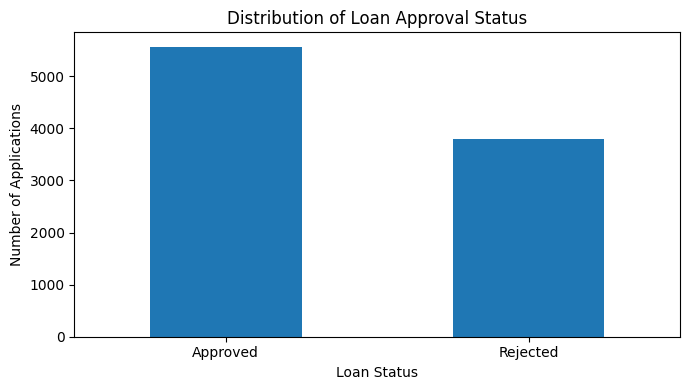

In [ ]:
# Prepare records with known loan outcomes for analysis
eda_df = df.dropna(subset=["loan_status"]).copy()

# Calculate the number of applications in each target category
status_counts = eda_df["loan_status"].value_counts()

# Calculate the percentage of applications in each category
status_percentages = (
    eda_df["loan_status"].value_counts(normalize=True) * 100
).round(2)

# Display the target distribution
print("Loan status counts:")
print(status_counts)

print("\nLoan status percentages:")
print(status_percentages)

# Plot the number of approved and rejected applications
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
status_counts.plot(kind="bar")
plt.title("Distribution of Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Summary statistics for numerical features:
                           count             mean             std       min  \
no_of_dependents          8844.0         2.495816        1.703209       0.0   
income_annum              9058.0   5045528.814308  2616989.191768  200000.0   
loan_amount               9109.0  13935393.566802  8335358.180311  300000.0   
loan_term                 9079.0        10.944157        5.711839       2.0   
cibil_score               8943.0       602.718271      159.778628     300.0   
residential_assets_value  9063.0   8871653.977712  5134776.853746       0.0   
commercial_assets_value   9160.0   4466637.554585  3850716.947617       0.0   
luxury_assets_value       9133.0  14147114.858207  8038869.221565  400000.0   
bank_asset_value          9126.0   5050021.915407  2926392.233855  100000.0   

                                25%         50%         75%         max  
no_of_dependents                1.0         2.0         4.0         5.0  
income_annum      

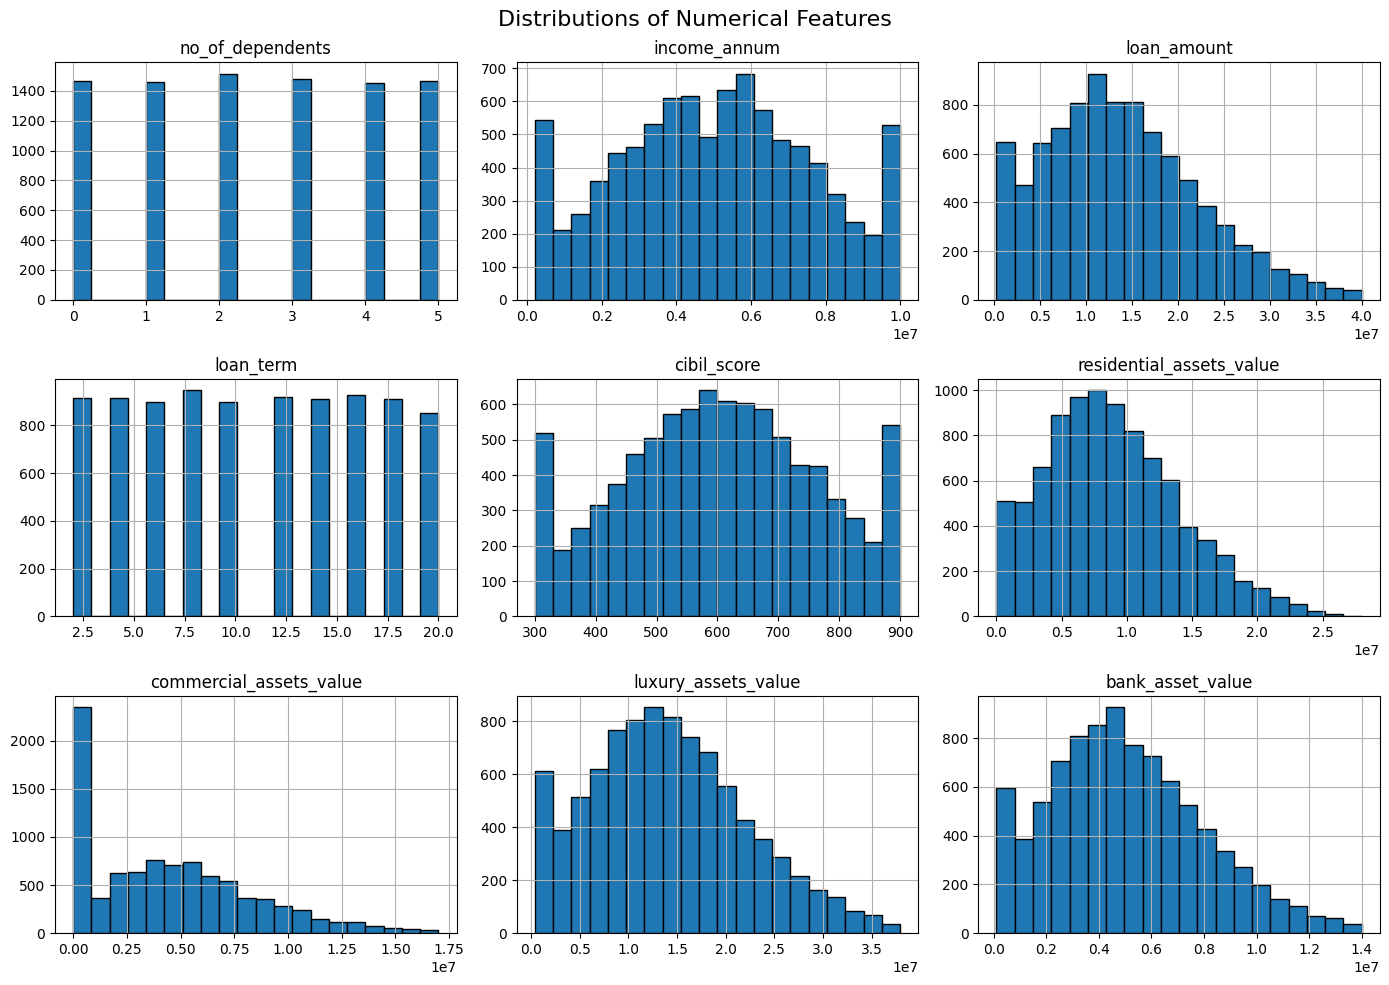

In [ ]:
#Select the numerical features for exploratory analysis
numeric_columns = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

#Display descriptive statistics for numerical features
print("Summary statistics for numerical features:")
print(eda_df[numeric_columns].describe().T.round(2))

#Plot histograms to inspect the feature distributions
import matplotlib.pyplot as plt

eda_df[numeric_columns].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


Distribution of education
education
Graduate        4559
Not Graduate    4533
NaN              273
Name: count, dtype: int64

Percentages:
education
Graduate        48.68
Not Graduate    48.40
NaN              2.92
Name: proportion, dtype: float64

Distribution of self_employed
self_employed
No     4615
Yes    4484
NaN     266
Name: count, dtype: int64

Percentages:
self_employed
No     49.28
Yes    47.88
NaN     2.84
Name: proportion, dtype: float64


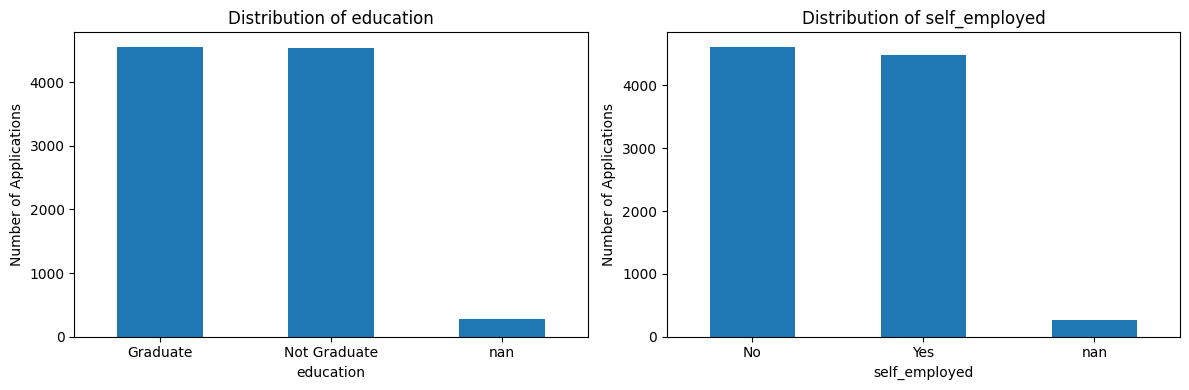

In [ ]:
#Calculate counts and percentages for the categorical features
categorical_columns = ["education", "self_employed"]

for col in categorical_columns:
    print("\nDistribution of", col)
    print(eda_df[col].value_counts(dropna=False))

    print("\nPercentages:")
    print((eda_df[col].value_counts(normalize=True, dropna=False) * 100).round(2))

#Plot the categorical feature distributions
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, categorical_columns):
    eda_df[col].value_counts(dropna=False).plot(kind="bar", ax=ax)
    ax.set_title("Distribution of " + col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Applications")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


Loan outcomes by education
Counts:
loan_status   Approved  Rejected
education                       
Graduate          2690      1869
Missing            169       104
Not Graduate      2705      1828

Percentages within each category:
loan_status   Approved  Rejected
education                       
Graduate         59.00     41.00
Missing          61.90     38.10
Not Graduate     59.67     40.33


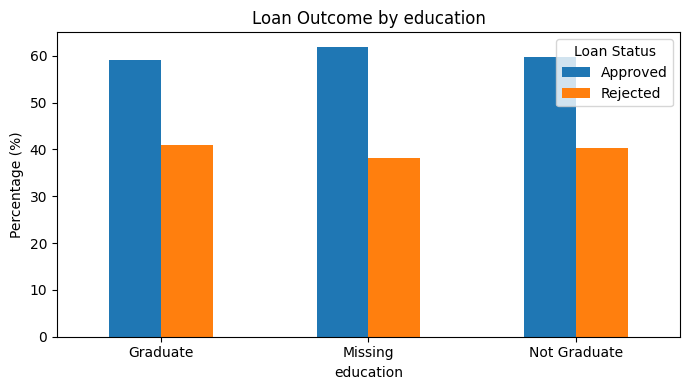


Loan outcomes by self_employed
Counts:
loan_status    Approved  Rejected
self_employed                    
Missing             158       108
No                 2730      1885
Yes                2676      1808

Percentages within each category:
loan_status    Approved  Rejected
self_employed                    
Missing           59.40     40.60
No                59.15     40.85
Yes               59.68     40.32


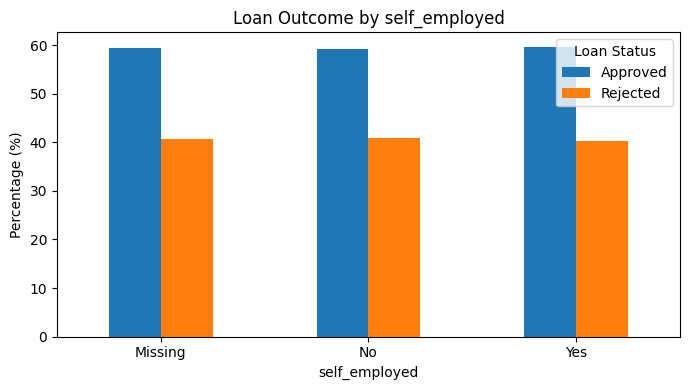

In [ ]:
#Compare loan outcomes across education and self-employment categories
categorical_columns = ["education", "self_employed"]

for col in categorical_columns:
    #Label missing feature values so they remain visible in the analysis
    feature_values = eda_df[col].fillna("Missing")

    #Calculate the number of approvals and rejections in each category
    counts = pd.crosstab(feature_values, eda_df["loan_status"])

    print("\nLoan outcomes by", col)
    print("Counts:")
    print(counts)

    #Calculate approval and rejection percentages within each category
    percentages = pd.crosstab(
        feature_values,
        eda_df["loan_status"],
        normalize="index"
    ) * 100

    print("\nPercentages within each category:")
    print(percentages.round(2))

    # Plot the percentage of each loan outcome by category
    percentages.plot(kind="bar", figsize=(7, 4))
    plt.title("Loan Outcome by " + col)
    plt.xlabel(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=0)
    plt.legend(title="Loan Status")
    plt.tight_layout()
    plt.show()

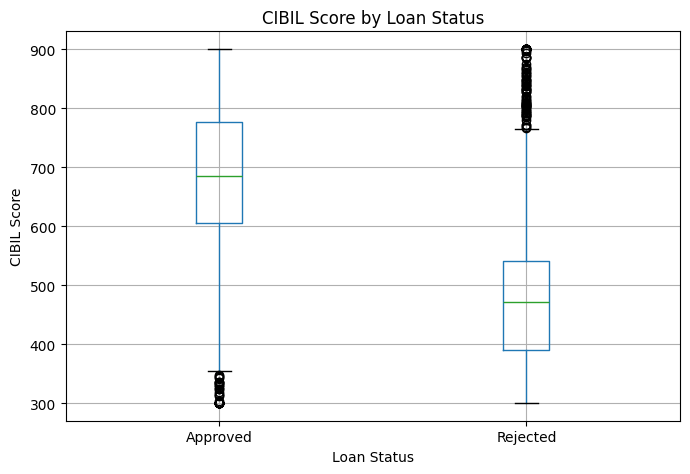

In [ ]:
#Create a figure and axes for the CIBIL score boxplot
fig, ax = plt.subplots(figsize=(7, 5))

#Draw the boxplot on the specified axes
eda_df.boxplot(
    column="cibil_score",
    by="loan_status",
    ax=ax
)

#Add a clear title and axis labels
ax.set_title("CIBIL Score by Loan Status")
fig.suptitle("")
ax.set_xlabel("Loan Status")
ax.set_ylabel("CIBIL Score")

#Adjust the layout and display the plot
fig.tight_layout()
plt.show()

Financial statistics by loan status:
            income_annum                        loan_amount               \
                   count        mean     median       count         mean   
loan_status                                                                
Approved            5387  5040170.78  5100000.0        5420  13944040.59   
Rejected            3671  5053391.45  5000000.0        3689  13922689.08   

                         
                 median  
loan_status              
Approved     13100000.0  
Rejected     13100000.0  


/tmp/ipykernel_4291/3573224013.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_4291/3573224013.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


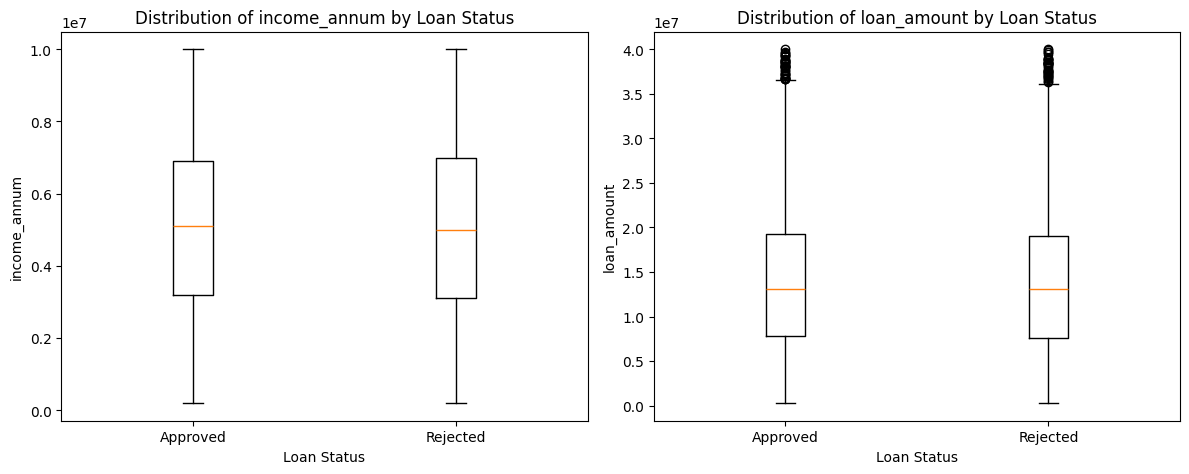

In [ ]:
#Calculate annual income and loan amount statistics by loan status
financial_features = ["income_annum", "loan_amount"]

print("Financial statistics by loan status:")
print(
    eda_df.groupby("loan_status")[financial_features]
    .agg(["count", "mean", "median"])
    .round(2)
)

#Compare the distributions using boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, financial_features):
    # Prepare non-missing values for each loan status
    approved_values = eda_df.loc[
        eda_df["loan_status"] == "Approved", col
    ].dropna()

    rejected_values = eda_df.loc[
        eda_df["loan_status"] == "Rejected", col
    ].dropna()

    #Plot the distributions side by side
    ax.boxplot(
        [approved_values, rejected_values],
        labels=["Approved", "Rejected"]
    )

    #Add titles and axis labels
    ax.set_title("Distribution of " + col + " by Loan Status")
    ax.set_xlabel("Loan Status")
    ax.set_ylabel(col)

#Adjust the layout and display both plots
plt.tight_layout()
plt.show()

Asset statistics by loan status:
            residential_assets_value                         \
                               count        mean     median   
loan_status                                                   
Approved                        5385  8855060.35  8300000.0   
Rejected                        3678  8895948.89  8400000.0   

            commercial_assets_value                         \
                              count        mean     median   
loan_status                                                  
Approved                       5431  4484183.39  4100000.0   
Rejected                       3729   4441083.4  4000000.0   

            luxury_assets_value                          bank_asset_value  \
                          count         mean      median            count   
loan_status                                                                 
Approved                   5413  14063643.08  13500000.0             5420   
Rejected                   3720 

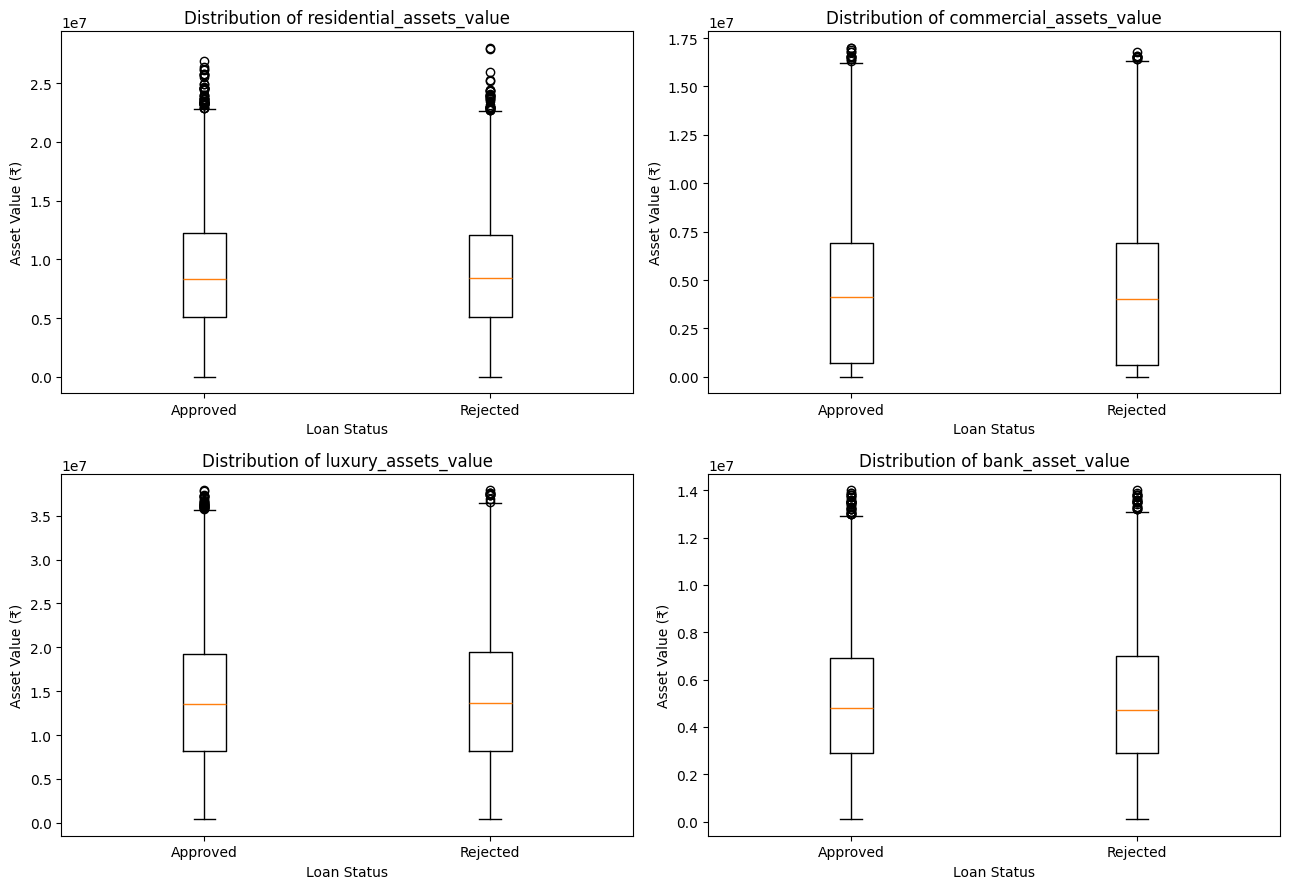

In [ ]:
#Select the asset features for comparison
asset_features = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

#Compare the mean and median asset values by loan status
print("Asset statistics by loan status:")
print(
    eda_df.groupby("loan_status")[asset_features]
    .agg(["count", "mean", "median"])
    .round(2)
)

#Plot asset distributions for approved and rejected applications
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flat, asset_features):
    #Collect non-missing values for each loan status
    approved_values = eda_df.loc[
        eda_df["loan_status"] == "Approved", col
    ].dropna()

    rejected_values = eda_df.loc[
        eda_df["loan_status"] == "Rejected", col
    ].dropna()

    #Compare the two distributions with a boxplot
    ax.boxplot(
        [approved_values, rejected_values],
        tick_labels=["Approved", "Rejected"]
    )

    #Label the plot
    ax.set_title("Distribution of " + col)
    ax.set_xlabel("Loan Status")
    ax.set_ylabel("Asset Value (₹)")

#Adjust spacing and display the plots
plt.tight_layout()
plt.show()

Loan outcomes by number of dependents:
loan_status       Approved  Rejected
no_of_dependents                    
0                      875       595
1                      903       556
2                      897       619
3                      849       632
4                      874       577
5                      848       619
Missing                318       203

Loan outcome percentages by number of dependents:
loan_status       Approved  Rejected
no_of_dependents                    
0                    59.52     40.48
1                    61.89     38.11
2                    59.17     40.83
3                    57.33     42.67
4                    60.23     39.77
5                    57.81     42.19
Missing              61.04     38.96

Loan outcomes by loan term:
loan_status  Approved  Rejected
loan_term                      
10                528       369
12                566       352
14                530       380
16                537       389
18                552  

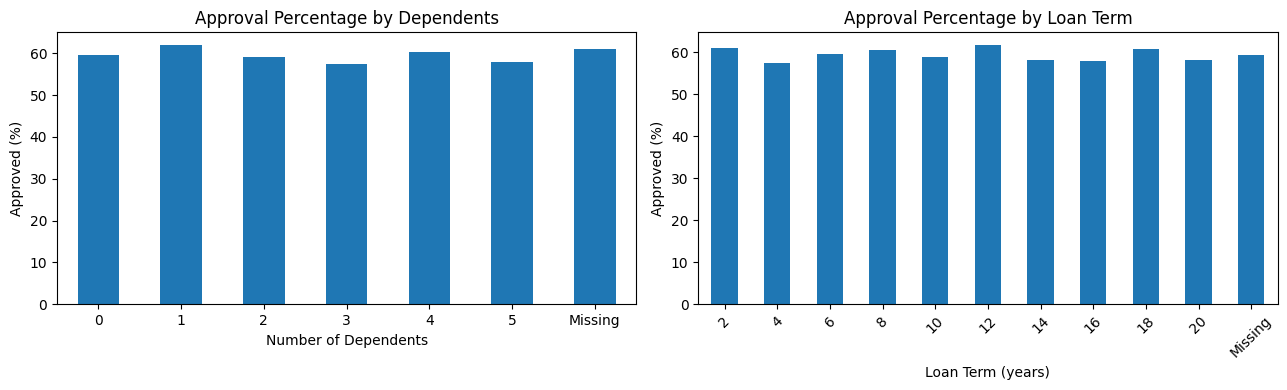

In [ ]:
# Convert dependent counts to strings so missing values can be labelled
dependents_values = (
    eda_df["no_of_dependents"].astype("string").fillna("Missing")
)

# Calculate counts and approval percentages by number of dependents
dependents_counts = pd.crosstab(
    dependents_values, eda_df["loan_status"]
)

dependents_percentages = pd.crosstab(
    dependents_values, eda_df["loan_status"], normalize="index"
) * 100

# Display loan outcomes for each dependent category
print("Loan outcomes by number of dependents:")
print(dependents_counts)

print("\nLoan outcome percentages by number of dependents:")
print(dependents_percentages.round(2))

# Convert loan terms to strings so missing values can be labelled
term_values = eda_df["loan_term"].astype("string").fillna("Missing")

# Calculate counts and approval percentages by loan term
term_counts = pd.crosstab(term_values, eda_df["loan_status"])

term_percentages = pd.crosstab(
    term_values, eda_df["loan_status"], normalize="index"
) * 100

# Display loan outcomes for each loan-term category
print("\nLoan outcomes by loan term:")
print(term_counts)

print("\nLoan outcome percentages by loan term:")
print(term_percentages.round(2))

# Arrange categories in numeric order, placing missing values last
dependents_order = ["0", "1", "2", "3", "4", "5", "Missing"]
dependents_percentages = dependents_percentages.reindex(dependents_order)

term_order = sorted(
    [value for value in term_percentages.index if value != "Missing"],
    key=int
)
if "Missing" in term_percentages.index:
    term_order.append("Missing")

term_percentages = term_percentages.reindex(term_order)

# Plot approval percentages for dependents and loan term
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

dependents_percentages["Approved"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Approval Percentage by Dependents")
axes[0].set_xlabel("Number of Dependents")
axes[0].set_ylabel("Approved (%)")
axes[0].tick_params(axis="x", rotation=0)

term_percentages["Approved"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Approval Percentage by Loan Term")
axes[1].set_xlabel("Loan Term (years)")
axes[1].set_ylabel("Approved (%)")
axes[1].tick_params(axis="x", rotation=45)

# Adjust plot spacing and display the charts
plt.tight_layout()
plt.show()

Correlation of numerical features with loan status:
cibil_score                 0.667
commercial_assets_value     0.005
loan_amount                 0.001
bank_asset_value            0.000
income_annum               -0.002
residential_assets_value   -0.004
loan_term                  -0.006
luxury_assets_value        -0.013
no_of_dependents           -0.015
Name: loan_status_encoded, dtype: float64


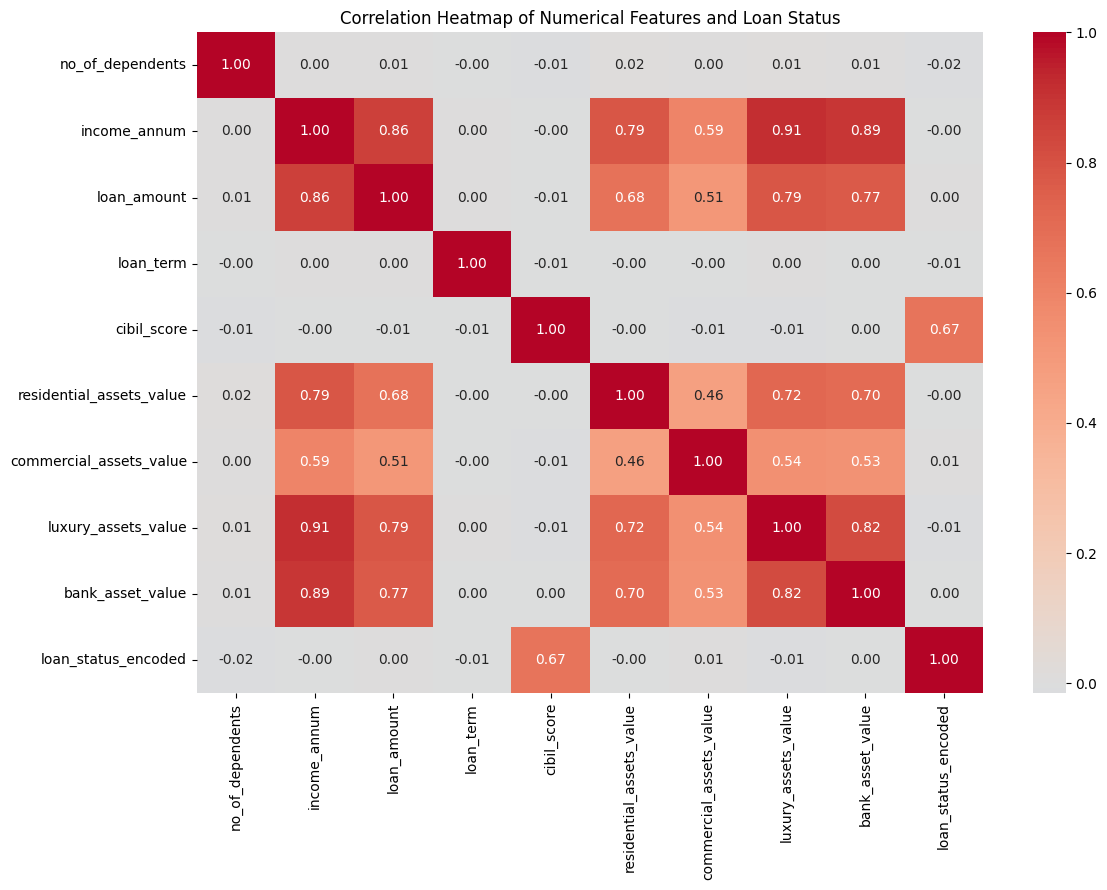

In [ ]:
#Select numeric features for the correlation analysis
numeric_columns = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

#Create a separate DataFrame for the correlation analysis
correlation_df = eda_df[numeric_columns].copy()

#Encode loan status as 1 for Approved and 0 for Rejected for correlation only
correlation_df["loan_status_encoded"] = eda_df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

#Calculate pairwise correlations between numerical features and loan status
correlation_matrix = correlation_df.corr()

# Display correlations between each numeric feature and loan status
print("Correlation of numerical features with loan status:")
print(
    correlation_matrix["loan_status_encoded"]
    .drop("loan_status_encoded")
    .sort_values(ascending=False)
    .round(3)
)

#Plot the complete correlation heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features and Loan Status")
plt.tight_layout()
plt.show()

## **Conclusion of EDA**

EDA showed that Approved applications represented 59.41% of labelled records, while Rejected applications represented 40.59%. Education and self-employment categories had similar approval rates. Approved applicants had substantially higher CIBIL scores than rejected applicants, and CIBIL score showed the strongest observed linear association with loan status (correlation = 0.667). Annual income, loan amount, asset values, dependents, and loan term showed weak individual linear correlations with loan status. These findings guided feature engineering, feature selection, and subsequent model development.

## **Feature Engineering and Selection**

Feature engineering was performed to create meaningful features from existing applicant information that could improve loan approval prediction. Three features were created: "total_assets", "loan_to_income_ratio", and "loan_to_asset_ratio". Their distributions, unusual values, and relationships with loan status were examined. Feature importance and validation-based model comparisons were then used to assess their usefulness.

In [ ]:
#Create a separate dataset for feature engineering
feature_df = model_df.copy()

#Select the four asset-value columns
asset_columns = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

#Calculate total assets only when all four asset values are available
feature_df["total_assets"] = (
    feature_df[asset_columns]
    .astype("float64")
    .sum(axis=1, min_count=4)
)

#Calculate the loan amount relative to annual income
feature_df["loan_to_income_ratio"] = (
    feature_df["loan_amount"].astype("float64") /
    feature_df["income_annum"].astype("float64")
)

#Treat zero or missing total assets as an undefined ratio
valid_total_assets = feature_df["total_assets"].where(
    feature_df["total_assets"] > 0
)

#Calculate the loan amount relative to total assets
feature_df["loan_to_asset_ratio"] = (
    feature_df["loan_amount"].astype("float64") /
    valid_total_assets
)

#Display summary statistics for the newly engineered features
engineered_features = [
    "total_assets",
    "loan_to_income_ratio",
    "loan_to_asset_ratio"
]

print("Summary of engineered features:")
print(feature_df[engineered_features].describe().T.round(3))

#Check missing and infinite values in the new features
print("\nMissing values in engineered features:")
print(feature_df[engineered_features].isnull().sum())

print("\nInfinite values in engineered features:")
print(
    np.isinf(
        feature_df[engineered_features].to_numpy(
            dtype="float64", na_value=np.nan
        )
    ).sum(axis=0)
)

#Confirm that the original master dataset remains unchanged
print("\nEngineered dataset shape:", feature_df.shape)
print("Original cleaned dataset shape:", df.shape)

Summary of engineered features:
                       count          mean           std         min  \
total_assets          8419.0  3.254827e+07  1.725453e+07  500000.000   
loan_to_income_ratio  8815.0  2.814000e+00  1.100000e+00       0.214   
loan_to_asset_ratio   8195.0  4.380000e-01  1.880000e-01       0.034   

                               25%           50%           75%           max  
total_assets          2.000000e+07  3.190000e+07  4.400000e+07  8.710000e+07  
loan_to_income_ratio  2.071000e+00  2.737000e+00  3.429000e+00  1.750000e+01  
loan_to_asset_ratio   3.160000e-01  4.200000e-01  5.330000e-01  2.875000e+00  

Missing values in engineered features:
total_assets             946
loan_to_income_ratio     550
loan_to_asset_ratio     1170
dtype: int64

Infinite values in engineered features:
[0 0 0]

Engineered dataset shape: (9365, 16)
Original cleaned dataset shape: (9500, 13)


In [ ]:
#Inspect the highest loan-to-income ratios and their source values
print("Highest loan-to-income ratios:")
print(
    feature_df.nlargest(10, "loan_to_income_ratio")[
        ["loan_id", "income_annum", "loan_amount", "loan_to_income_ratio"]
    ]
)

#Inspect the highest loan-to-asset ratios and their source values
print("\nHighest loan-to-asset ratios:")
print(
    feature_df.nlargest(10, "loan_to_asset_ratio")[
        ["loan_id", "loan_amount", "total_assets", "loan_to_asset_ratio"]
    ]
)

#Examine key percentiles for both ratios
print("\nLoan-to-income ratio percentiles:")
print(
    feature_df["loan_to_income_ratio"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(3)
)

print("\nLoan-to-asset ratio percentiles:")
print(
    feature_df["loan_to_asset_ratio"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .round(3)
)

Highest loan-to-income ratios:
      loan_id  income_annum  loan_amount  loan_to_income_ratio
6746     6747        200000      3500000                  17.5
4180     4181        200000      3400000                  17.0
1773     1774        200000      3100000                  15.5
2282     2283        200000      3000000                  15.0
4703     4704        200000      2800000                  14.0
5977     5978        200000      2700000                  13.5
1820     1821        200000      2600000                  13.0
1892     1893        200000      2600000                  13.0
3418     3419        200000      2600000                  13.0
7132     7133        200000      2500000                  12.5

Highest loan-to-asset ratios:
      loan_id  loan_amount  total_assets  loan_to_asset_ratio
5336     5337      2300000      800000.0             2.875000
2282     2283      3000000     1100000.0             2.727273
3326     3327      1600000      600000.0             2.6666

In [ ]:
#Compare engineered feature statistics for approved and rejected applications
engineered_features = [
    "total_assets",
    "loan_to_income_ratio",
    "loan_to_asset_ratio"
]

print("Engineered feature statistics by loan status:")
print(
    feature_df.groupby("loan_status")[engineered_features]
    .agg(["count", "mean", "median"])
    .round(3)
)

Engineered feature statistics by loan status:
            total_assets                           loan_to_income_ratio  \
                   count          mean      median                count   
loan_status                                                               
Approved            4980  3.246797e+07  31750000.0                 5248   
Rejected            3439  3.266455e+07  32100000.0                 3567   

                          loan_to_asset_ratio                
              mean median               count   mean median  
loan_status                                                  
Approved     2.815  2.741                4856  0.441  0.421  
Rejected     2.811  2.726                3339  0.435  0.419  


In [ ]:
#Import the tools needed for feature importance analysis
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

#Separate the input features from the loan approval target
feature_columns = feature_df.drop(columns=["loan_id", "loan_status"])
target = feature_df["loan_status"]

#Identify numerical and categorical input features
numeric_features_selection = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value",
    "total_assets",
    "loan_to_income_ratio",
    "loan_to_asset_ratio"
]

categorical_features_selection = ["education", "self_employed"]

#Split the data while preserving the target class proportions
X_selection_train, X_selection_test, y_selection_train, y_selection_test = (
    train_test_split(
        feature_columns,
        target,
        test_size=0.20,
        random_state=42,
        stratify=target
    )
)

#Impute missing numerical values using training-set medians
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

#Impute missing categories and encode them using training data
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

#Combine the numerical and categorical preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features_selection),
    ("categorical", categorical_pipeline, categorical_features_selection)
])

#Prepare the training data and learn the preprocessing transformations
X_selection_train_processed = preprocessor.fit_transform(X_selection_train)

#Fit a Random Forest classifier using training data only
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_selection_train_processed, y_selection_train)

#Obtain the names of the features after preprocessing
encoded_feature_names = preprocessor.get_feature_names_out()

# Retrieve the importance score for each processed feature
importance_df = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Importance": rf_model.feature_importances_
})

#Group one-hot encoded categories under their original feature names
importance_df["Original Feature"] = importance_df["Feature"].apply(
    lambda name: (
        name.split("__", 1)[1].split("_", 1)[0]
        if name.startswith("categorical__")
        else name.split("__", 1)[1]
    )
)

#Combine importance scores for categories belonging to the same feature
grouped_importance = (
    importance_df.groupby("Original Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

#Display the feature importance ranking
print("Feature importance ranking:")
print(grouped_importance.round(4))

Feature importance ranking:
Original Feature
cibil_score                 0.5325
loan_to_income_ratio        0.0480
loan_to_asset_ratio         0.0475
residential_assets_value    0.0469
luxury_assets_value         0.0463
total_assets                0.0436
loan_amount                 0.0434
bank_asset_value            0.0427
commercial_assets_value     0.0381
income_annum                0.0366
loan_term                   0.0285
no_of_dependents            0.0215
education                   0.0124
self                        0.0120
Name: Importance, dtype: float64


In [ ]:
#Correctly group encoded categories under their original feature names
def get_original_feature(name):
    #Return the original name for a numerical feature
    if name.startswith("numeric__"):
        return name.split("__", 1)[1]

    #Group one-hot encoded education categories together
    if name.startswith("categorical__"):
        encoded_name = name.split("__", 1)[1]

        for col in categorical_features_selection:
            if encoded_name.startswith(col + "_"):
                return col

        return encoded_name

    return name

#Assign the correct original feature name to each importance score
importance_df["Original Feature"] = importance_df["Feature"].apply(
    get_original_feature
)

#Combine category-level importance and sort from highest to lowest
grouped_importance = (
    importance_df.groupby("Original Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

#Display the corrected feature-importance ranking
print("Corrected feature importance ranking:")
print(grouped_importance.round(4))

Corrected feature importance ranking:
Original Feature
cibil_score                 0.5325
loan_to_income_ratio        0.0480
loan_to_asset_ratio         0.0475
residential_assets_value    0.0469
luxury_assets_value         0.0463
total_assets                0.0436
loan_amount                 0.0434
bank_asset_value            0.0427
commercial_assets_value     0.0381
income_annum                0.0366
loan_term                   0.0285
no_of_dependents            0.0215
education                   0.0124
self_employed               0.0120
Name: Importance, dtype: float64


In [ ]:
#Import tools for validation and permutation importance
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

#Split the existing training data into a model-fitting set and a validation set
X_fit, X_val, y_fit, y_val = train_test_split(
    X_selection_train,
    y_selection_train,
    test_size=0.20,
    random_state=42,
    stratify=y_selection_train
)

#Create a pipeline for numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

#Create a pipeline for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

#Combine preprocessing for numeric and categorical features
validation_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features_selection),
    ("categorical", categorical_pipeline, categorical_features_selection)
])

#Build a Random Forest pipeline for validation
validation_model = Pipeline([
    ("preprocessor", validation_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

#Fit the complete pipeline using only the model-fitting data
validation_model.fit(X_fit, y_fit)

#Measure how shuffling each original feature affects validation accuracy
permutation_results = permutation_importance(
    validation_model,
    X_val,
    y_val,
    scoring="accuracy",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

#Summarize each feature's mean importance and variability
permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Mean Importance": permutation_results.importances_mean,
    "Standard Deviation": permutation_results.importances_std
}).sort_values("Mean Importance", ascending=False)

#Display the permutation importance ranking
print("Permutation importance on validation data:")
print(permutation_df.round(4).to_string(index=False))

Permutation importance on validation data:
                 Feature  Mean Importance  Standard Deviation
             cibil_score           0.3044              0.0097
residential_assets_value           0.0033              0.0013
        bank_asset_value           0.0032              0.0007
     luxury_assets_value           0.0014              0.0015
    loan_to_income_ratio           0.0011              0.0009
           self_employed           0.0009              0.0010
            income_annum           0.0007              0.0011
 commercial_assets_value           0.0007              0.0011
            total_assets           0.0004              0.0012
        no_of_dependents           0.0001              0.0010
               education           0.0001              0.0008
               loan_term           0.0000              0.0008
             loan_amount          -0.0005              0.0009
     loan_to_asset_ratio          -0.0009              0.0012


In [ ]:
#Import the tools needed to compare feature sets
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd

#Define the original numerical features
original_numeric_features = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

#Define the engineered features to evaluate
engineered_feature_options = {
    "Original features only": [],
    "Add total assets": ["total_assets"],
    "Add loan-to-income ratio": ["loan_to_income_ratio"],
    "Add loan-to-asset ratio": ["loan_to_asset_ratio"],
    "Add all engineered features": [
        "total_assets",
        "loan_to_income_ratio",
        "loan_to_asset_ratio"
    ]
}

#Store results for every feature-set comparison
comparison_results = []

#Train and validate one model for each feature set
for model_name, extra_features in engineered_feature_options.items():

# Select numerical and categorical features for this comparison
    selected_numeric = original_numeric_features + extra_features
    selected_features = selected_numeric + categorical_features_selection

# Create numeric and categorical preprocessing pipelines
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

# Combine preprocessing for the selected features
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, selected_numeric),
        ("categorical", categorical_pipeline, categorical_features_selection)
    ])

# Build a Random Forest pipeline
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ])

# Fit only on the fitting subset
    model_pipeline.fit(
        X_fit[selected_features],
        y_fit
    )

# Predict outcomes on the validation subset
    validation_predictions = model_pipeline.predict(
        X_val[selected_features]
    )

# Calculate validation metrics
    comparison_results.append({
        "Feature Set": model_name,
        "Accuracy": accuracy_score(y_val, validation_predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, validation_predictions
        ),
        "Macro F1": f1_score(
            y_val, validation_predictions, average="macro"
        )
    })

# Display the models from best to worst by balanced accuracy
comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(
    "Balanced Accuracy",
    ascending=False
)

print("Validation comparison of feature sets:")
print(comparison_df.round(4).to_string(index=False))

Validation comparison of feature sets:
                Feature Set  Accuracy  Balanced Accuracy  Macro F1
           Add total assets    0.8326             0.8158    0.8221
   Add loan-to-income ratio    0.8319             0.8150    0.8213
Add all engineered features    0.8319             0.8147    0.8212
     Original features only    0.8299             0.8125    0.8190
    Add loan-to-asset ratio    0.8286             0.8114    0.8177


## **Conclusion of Feature Engineering and Selection**

Random Forest feature importance and permutation importance identified "cibil_score" as the most influential feature. Among the three engineered features, "total_assets" produced the best validation results when added to the original features, achieving 83.26% accuracy, 81.58% balanced accuracy, and 82.21% macro F1-score. The "loan_to_income_ratio" provided a smaller improvement, while "loan_to_asset_ratio" reduced the validation scores. Therefore, "total_assets" was retained for model development, and the two ratio features were excluded from the selected feature set.

## **Model Development and Comparison**

Three classification algorithms, Logistic Regression, Decision Tree, and Random Forest, were selected to predict loan approval status. The models used the original applicant features and the engineered feature total_assets. Numerical and categorical data were preprocessed through pipelines, and each model was trained on the fitting dataset and evaluated on the same validation dataset.

Accuracy, balanced accuracy, precision, recall, and macro F1-score were used to compare the models and identify the most suitable classifier.

In [ ]:
# Import the algorithms and evaluation metrics needed for model comparison
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Select the original numerical features and the chosen engineered feature
selected_numeric = original_numeric_features + ["total_assets"]
selected_categorical = ["education", "self_employed"]
selected_features = selected_numeric + selected_categorical

# Select the same features from the fitting and validation datasets
X_fit_model = X_fit[selected_features]
X_val_model = X_val[selected_features]

# Impute missing numeric values and standardize their scales
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Impute missing categories and encode them numerically
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing for numerical and categorical features
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, selected_numeric),
    ("categorical", categorical_pipeline, selected_categorical)
])

# Define classification algorithms for comparison
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(
        min_samples_leaf=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

# Train each model on the fitting data and evaluate it on validation data
results = []
trained_models = {}

for name, classifier in models.items():
    # Create a complete pipeline for this classifier
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Fit preprocessing and model using the fitting subset only
    model_pipeline.fit(X_fit_model, y_fit)

    # Predict loan outcomes for the validation subset
    predictions = model_pipeline.predict(X_val_model)

    # Record several metrics rather than relying on accuracy alone
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predictions),
        "Precision (Approved)": precision_score(
            y_val, predictions, pos_label="Approved", zero_division=0
        ),
        "Recall (Approved)": recall_score(
            y_val, predictions, pos_label="Approved", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro"
        )
    })

    # Save the trained pipeline for later inspection
    trained_models[name] = model_pipeline

# Display model comparison, ordered by macro F1
comparison_results = pd.DataFrame(results).sort_values(
    "Macro F1", ascending=False
)

print("Classification model comparison on validation data:")
print(comparison_results.round(4).to_string(index=False))

Classification model comparison on validation data:
              Model  Accuracy  Balanced Accuracy  Precision (Approved)  Recall (Approved)  Macro F1
      Random Forest    0.8326             0.8153                0.8279             0.9068    0.8218
Logistic Regression    0.8239             0.8067                0.8222             0.8979    0.8128
      Decision Tree    0.7799             0.7631                0.7931             0.8519    0.7672


### **Conclusion of Model Development**

This project uses classification to predict loan approval status (Approved or Rejected). Three algorithms were compared: Logistic Regression, Decision Tree, and Random Forest.
Random Forest performed best on the validation data, achieving 83.26% accuracy, 81.53% balanced accuracy, and 82.18% macro F1-score. Logistic Regression achieved 82.39% accuracy, while Decision Tree achieved 77.99%.

Random Forest was selected because it performed best across the evaluated metrics and can capture nonlinear relationships between applicant features.
The selected feature set includes the original input features and the engineered feature total_assets. The loan_to_income_ratio and loan_to_asset_ratio features were excluded from the selected model.

The test set was kept separate during model selection for evaluation in the next phase.

Final test-set evaluation
Accuracy: 0.8532
Balanced accuracy: 0.8412
Macro F1-score: 0.8456

Classification report:
              precision    recall  f1-score   support

    Approved       0.86      0.90      0.88      1113
    Rejected       0.85      0.78      0.81       760

    accuracy                           0.85      1873
   macro avg       0.85      0.84      0.85      1873
weighted avg       0.85      0.85      0.85      1873

Confusion matrix (rows = actual, columns = predicted)
Class order: Rejected, Approved
[[ 591  169]
 [ 106 1007]]

ROC-AUC: 0.8987


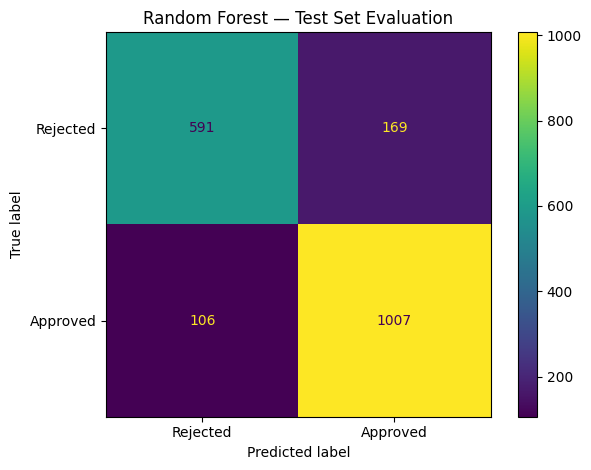

In [ ]:
# Import tools for final model evaluation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    f1_score
)
import matplotlib.pyplot as plt

# Select the original numeric features plus total assets
selected_numeric_final = original_numeric_features + ["total_assets"]
selected_categorical_final = ["education", "self_employed"]
selected_features_final = (
    selected_numeric_final + selected_categorical_final
)

# Prepare the training and testing features
X_final_train = X_selection_train[selected_features_final].copy()
X_final_test = X_selection_test[selected_features_final].copy()

# Impute missing numeric values and standardize them using training data
numeric_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Impute missing categorical values and encode the categories
categorical_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing for numeric and categorical features
preprocessor_final = ColumnTransformer([
    ("numeric", numeric_pipeline_final, selected_numeric_final),
    ("categorical", categorical_pipeline_final, selected_categorical_final)
])

# Create the selected Random Forest model
final_model = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model using the full training split only
final_model.fit(X_final_train, y_selection_train)

# Predict loan outcomes on the untouched test set
y_final_pred = final_model.predict(X_final_test)

# Calculate overall test metrics
print("Final test-set evaluation")
print("Accuracy:", round(
    accuracy_score(y_selection_test, y_final_pred), 4
))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_selection_test, y_final_pred), 4
))
print("Macro F1-score:", round(
    f1_score(y_selection_test, y_final_pred, average="macro"), 4
))

# Display precision, recall, and F1-score for both classes
print("\nClassification report:")
print(classification_report(
    y_selection_test,
    y_final_pred,
    labels=["Approved", "Rejected"],
    zero_division=0
))

# Calculate confusion matrix with a clearly defined class order
cm = confusion_matrix(
    y_selection_test,
    y_final_pred,
    labels=["Rejected", "Approved"]
)

print("Confusion matrix (rows = actual, columns = predicted)")
print("Class order: Rejected, Approved")
print(cm)

# Calculate ROC-AUC using Approved as the positive class
final_probabilities = final_model.predict_proba(X_final_test)
class_names = list(final_model.named_steps["classifier"].classes_)
approved_index = class_names.index("Approved")

roc_auc = roc_auc_score(
    (y_selection_test == "Approved").astype(int),
    final_probabilities[:, approved_index]
)

print("\nROC-AUC:", round(roc_auc, 4))

# Visualize the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
).plot()

plt.title("Random Forest — Test Set Evaluation")
plt.tight_layout()
plt.show()

### **Conclusion of Model Evaluation**

The Random Forest classifier achieved 85.32% accuracy, 84.12% balanced accuracy, 84.56% macro F1-score, and 0.8987 ROC-AUC on the test set. It correctly classified 1,007 Approved and 591 Rejected applications.

The model incorrectly classified 106 Approved applications as Rejected and 169 Rejected applications as Approved. Recall was higher for Approved applications (90%) than for Rejected applications (78%), indicating that the model identifies approved applications more effectively.


# **Model Comparision**
Three classification algorithms, Logistic Regression, Decision Tree, and Random Forest, were compared using validation data. Random Forest achieved the best performance, with 83.26% accuracy, 81.53% balanced accuracy, and 82.18% macro F1-score. Logistic Regression achieved 82.39% accuracy, while Decision Tree achieved 77.99%. Therefore, Random Forest was selected for final evaluation because it performed best across the three main metrics.

# **Additional Experiments for Model Improvement and Performance Optimization**

Several experiments were conducted to improve the original Random Forest model, including hyperparameter tuning, Gradient Boosting, HistGradientBoosting, decision threshold optimization, and a soft-voting ensemble.

### Hyperparameter Tuning and Performance Comparison of Random Forest

RandomizedSearchCV was used with 3-fold stratified cross-validation to test different Random Forest configurations. The best configuration achieved a mean cross-validation balanced accuracy of 82.85%.

On the test set, the tuned model retained 85.32% accuracy, 84.12% balanced accuracy, and 84.56% macro F1-score, while ROC-AUC decreased slightly from 89.87% to 89.79%. Since the tuning did not improve the test results, the original Random Forest was retained as the baseline model.

In [ ]:
# Import the train-test splitting function
from sklearn.model_selection import train_test_split

# Separate input features and target
feature_columns = feature_df.drop(
    columns=["loan_id", "loan_status"]
)
target = feature_df["loan_status"]

# Recreate the training and testing datasets
X_selection_train, X_selection_test, y_selection_train, y_selection_test = (
    train_test_split(
        feature_columns,
        target,
        test_size=0.20,
        random_state=42,
        stratify=target
    )
)

# Define the feature set selected for the model
original_numeric_features = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

selected_numeric_final = original_numeric_features + ["total_assets"]
selected_categorical_final = ["education", "self_employed"]

selected_features_final = (
    selected_numeric_final + selected_categorical_final
)

# Verify the recreated datasets
print("Training features:", X_selection_train.shape)
print("Testing features:", X_selection_test.shape)
print("Training target:", y_selection_train.shape)
print("Testing target:", y_selection_test.shape)

Training features: (7492, 14)
Testing features: (1873, 14)
Training target: (7492,)
Testing target: (1873,)


In [ ]:
# Import tools for faster Random Forest tuning
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Select the features used in the existing model
X_tune = X_selection_train[selected_features_final]
y_tune = y_selection_train

# Preprocess numerical features
numeric_pipeline_tune = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_pipeline_tune = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor_tune = ColumnTransformer([
    ("numeric", numeric_pipeline_tune, selected_numeric_final),
    ("categorical", categorical_pipeline_tune, selected_categorical_final)
])

# Create the Random Forest pipeline
rf_pipeline_tune = Pipeline([
    ("preprocessor", preprocessor_tune),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Define a smaller parameter search
parameter_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.7],
    "classifier__class_weight": [None, "balanced"]
}

# Use 3-fold stratified cross-validation
cross_validation = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Search only 8 parameter combinations
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline_tune,
    param_distributions=parameter_grid,
    n_iter=8,
    scoring="balanced_accuracy",
    cv=cross_validation,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True
)

# Fit using training data only
rf_search.fit(X_tune, y_tune)

# Display the best configuration and cross-validation score
print("\nBest parameters:")
print(rf_search.best_params_)

print("\nBest mean cross-validation balanced accuracy:")
print(round(rf_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20, 'classifier__class_weight': None}

Best mean cross-validation balanced accuracy:
0.8285


Tuned Random Forest Test Results
Accuracy: 0.8532
Balanced Accuracy: 0.8412
Macro F1-score: 0.8456

Classification Report:
              precision    recall  f1-score   support

    Approved       0.86      0.90      0.88      1113
    Rejected       0.85      0.78      0.81       760

    accuracy                           0.85      1873
   macro avg       0.85      0.84      0.85      1873
weighted avg       0.85      0.85      0.85      1873

Confusion Matrix (actual rows, predicted columns)
Class order: Rejected, Approved
[[ 591  169]
 [ 106 1007]]

ROC-AUC: 0.8979


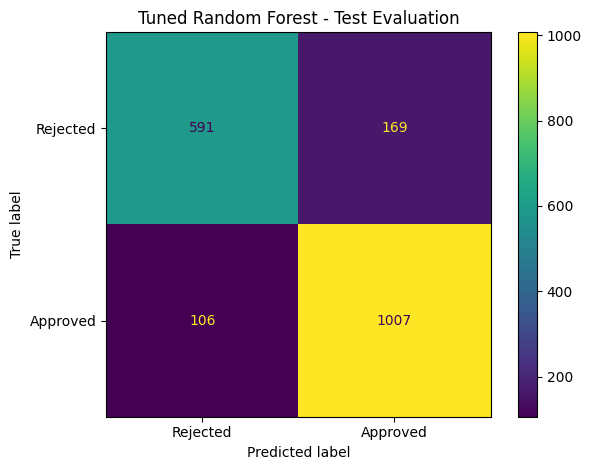


Original vs Tuned Random Forest
           Metric  Original Random Forest  Tuned Random Forest
         Accuracy                  0.8532               0.8532
Balanced Accuracy                  0.8412               0.8412
   Macro F1-score                  0.8456               0.8456
          ROC-AUC                  0.8987               0.8979


In [ ]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt
import pandas as pd

# Use the best model found by RandomizedSearchCV
tuned_model = rf_search.best_estimator_

# Prepare the test features
X_tuned_test = X_selection_test[selected_features_final]

# Predict loan status on the test data
y_tuned_pred = tuned_model.predict(X_tuned_test)

# Calculate test metrics
tuned_accuracy = accuracy_score(y_selection_test, y_tuned_pred)
tuned_balanced_accuracy = balanced_accuracy_score(
    y_selection_test, y_tuned_pred
)
tuned_macro_f1 = f1_score(
    y_selection_test, y_tuned_pred, average="macro"
)

print("Tuned Random Forest Test Results")
print("Accuracy:", round(tuned_accuracy, 4))
print("Balanced Accuracy:", round(tuned_balanced_accuracy, 4))
print("Macro F1-score:", round(tuned_macro_f1, 4))

# Display performance for each class
print("\nClassification Report:")
print(classification_report(
    y_selection_test,
    y_tuned_pred,
    labels=["Approved", "Rejected"],
    zero_division=0
))

# Create the confusion matrix
cm_tuned = confusion_matrix(
    y_selection_test,
    y_tuned_pred,
    labels=["Rejected", "Approved"]
)

print("Confusion Matrix (actual rows, predicted columns)")
print("Class order: Rejected, Approved")
print(cm_tuned)

# Calculate ROC-AUC
tuned_probabilities = tuned_model.predict_proba(X_tuned_test)
class_names = list(tuned_model.named_steps["classifier"].classes_)
approved_index = class_names.index("Approved")

tuned_roc_auc = roc_auc_score(
    (y_selection_test == "Approved").astype(int),
    tuned_probabilities[:, approved_index]
)

print("\nROC-AUC:", round(tuned_roc_auc, 4))

# Plot the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Rejected", "Approved"]
).plot()

plt.title("Tuned Random Forest - Test Evaluation")
plt.tight_layout()
plt.show()

# Compare against the original model's recorded test results
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1-score",
        "ROC-AUC"
    ],
    "Original Random Forest": [
        0.8532, 0.8412, 0.8456, 0.8987
    ],
    "Tuned Random Forest": [
        tuned_accuracy,
        tuned_balanced_accuracy,
        tuned_macro_f1,
        tuned_roc_auc
    ]
})

print("\nOriginal vs Tuned Random Forest")
print(comparison.round(4).to_string(index=False))

### Gradient Boosting Comparison

Gradient Boosting was tested as an alternative to Random Forest using the same validation data. It achieved 82.99% accuracy, 81.17% balanced accuracy, and 81.86% macro F1-score. Although its recall for Approved applications was slightly higher at 90.80%, its overall performance was lower than Random Forest. Therefore, Random Forest was retained as the preferred model.

In [ ]:
# Import Gradient Boosting and evaluation metrics
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Select the original numerical features plus total assets
selected_numeric = original_numeric_features + ["total_assets"]
selected_categorical = ["education", "self_employed"]
selected_features = selected_numeric + selected_categorical

# Prepare fitting and validation data
X_fit_model = X_fit[selected_features]
X_val_model = X_val[selected_features]

# Handle missing numerical values
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Handle missing categorical values and encode them
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, selected_numeric),
    ("categorical", categorical_pipeline, selected_categorical)
])

# Create the Gradient Boosting model
gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Train on the fitting data
gradient_model.fit(X_fit_model, y_fit)

# Predict outcomes on validation data
gradient_predictions = gradient_model.predict(X_val_model)

# Calculate validation metrics
gradient_results = {
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_val, gradient_predictions),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, gradient_predictions
    ),
    "Precision (Approved)": precision_score(
        y_val, gradient_predictions,
        pos_label="Approved",
        zero_division=0
    ),
    "Recall (Approved)": recall_score(
        y_val, gradient_predictions,
        pos_label="Approved",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, gradient_predictions, average="macro"
    )
}

# Compare with the original Random Forest on the same validation data
comparison = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "Accuracy": 0.8326,
        "Balanced Accuracy": 0.8153,
        "Precision (Approved)": 0.8279,
        "Recall (Approved)": 0.9068,
        "Macro F1": 0.8218
    },
    gradient_results
])

print("Validation comparison:")
print(comparison.round(4).to_string(index=False))

Validation comparison:
                 Model  Accuracy  Balanced Accuracy  Precision (Approved)  Recall (Approved)  Macro F1
Original Random Forest    0.8326             0.8153                0.8279             0.9068    0.8218
     Gradient Boosting    0.8299             0.8117                0.8238             0.9080    0.8186


## **Decision Threshold Optimization**

Different classification thresholds were tested using validation data to investigate the trade-off between identifying Approved and Rejected applications. The default threshold of 0.50 achieved the highest balanced accuracy of 81.53%. A threshold of 0.58 increased Rejected recall from 72.37% to 74.34%, but slightly reduced accuracy and balanced accuracy. Therefore, the default threshold was retained.

In [ ]:
# Import evaluation metrics and model components
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)
import numpy as np
import pandas as pd

# Select the features used by our Random Forest
selected_numeric = original_numeric_features + ["total_assets"]
selected_categorical = ["education", "self_employed"]
selected_features = selected_numeric + selected_categorical

X_fit_model = X_fit[selected_features]
X_val_model = X_val[selected_features]

# Prepare numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, selected_numeric),
    ("categorical", categorical_pipeline, selected_categorical)
])

# Train Random Forest using fitting data only
threshold_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

threshold_model.fit(X_fit_model, y_fit)

# Get estimated probabilities for the Approved class
probabilities = threshold_model.predict_proba(X_val_model)
classes = list(threshold_model.named_steps["classifier"].classes_)
approved_index = classes.index("Approved")
approved_probabilities = probabilities[:, approved_index]

# Compare several probability thresholds
threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.02):
    predictions = np.where(
        approved_probabilities >= threshold,
        "Approved",
        "Rejected"
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Macro F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Recall (Rejected)": recall_score(
            y_val, predictions,
            pos_label="Rejected",
            zero_division=0
        ),
        "Recall (Approved)": recall_score(
            y_val, predictions,
            pos_label="Approved",
            zero_division=0
        )
    })

# Display the best thresholds by balanced accuracy
threshold_df = pd.DataFrame(threshold_results)

print("Top thresholds by balanced accuracy:")
print(
    threshold_df.sort_values(
        "Balanced Accuracy", ascending=False
    ).head(10).round(4).to_string(index=False)
)

Top thresholds by balanced accuracy:
 Threshold  Accuracy  Balanced Accuracy  Macro F1  Recall (Rejected)  Recall (Approved)
      0.50    0.8326             0.8153    0.8218             0.7237             0.9068
      0.58    0.8286             0.8150    0.8194             0.7434             0.8866
      0.48    0.8326             0.8145    0.8214             0.7188             0.9102
      0.60    0.8259             0.8141    0.8174             0.7516             0.8765
      0.52    0.8306             0.8138    0.8200             0.7253             0.9024
      0.46    0.8312             0.8128    0.8199             0.7155             0.9102
      0.54    0.8286             0.8124    0.8182             0.7270             0.8979
      0.62    0.8225             0.8121    0.8145             0.7566             0.8676
      0.56    0.8266             0.8115    0.8166             0.7319             0.8911
      0.44    0.8299             0.8112    0.8183             0.7122             0.

## **HistGradientBoosting Classifier**

HistGradientBoosting was evaluated as an alternative tree-based classification algorithm using the same fitting and validation datasets. It achieved 83.06% accuracy, 81.44% balanced accuracy, and 82.02% macro F1-score. Its performance was close to Random Forest but did not surpass it, so Random Forest remained the preferred model.

In [ ]:
# Import HistGradientBoosting and evaluation metrics
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Define the selected features
selected_numeric = original_numeric_features + ["total_assets"]
selected_categorical = ["education", "self_employed"]
selected_features = selected_numeric + selected_categorical

# Prepare the same fitting and validation datasets
X_fit_model = X_fit[selected_features]
X_val_model = X_val[selected_features]

# Impute missing numerical values
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Impute and encode categorical values
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, selected_numeric),
    ("categorical", categorical_pipeline, selected_categorical)
])

# Create the HistGradientBoosting pipeline
hist_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Train using fitting data only
hist_model.fit(X_fit_model, y_fit)

# Predict on validation data
hist_predictions = hist_model.predict(X_val_model)

# Calculate validation metrics
hist_results = {
    "Model": "HistGradientBoosting",
    "Accuracy": accuracy_score(y_val, hist_predictions),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, hist_predictions
    ),
    "Precision (Approved)": precision_score(
        y_val, hist_predictions,
        pos_label="Approved", zero_division=0
    ),
    "Recall (Approved)": recall_score(
        y_val, hist_predictions,
        pos_label="Approved", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, hist_predictions, average="macro"
    )
}

# Compare against the existing Random Forest and Gradient Boosting
comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": 0.8326,
        "Balanced Accuracy": 0.8153,
        "Precision (Approved)": 0.8279,
        "Recall (Approved)": 0.9068,
        "Macro F1": 0.8218
    },
    {
        "Model": "Gradient Boosting",
        "Accuracy": 0.8299,
        "Balanced Accuracy": 0.8117,
        "Precision (Approved)": 0.8238,
        "Recall (Approved)": 0.9080,
        "Macro F1": 0.8186
    },
    hist_results
])

print("Model comparison on validation data:")
print(comparison.round(4).to_string(index=False))

Model comparison on validation data:
               Model  Accuracy  Balanced Accuracy  Precision (Approved)  Recall (Approved)  Macro F1
       Random Forest    0.8326             0.8153                0.8279             0.9068    0.8218
   Gradient Boosting    0.8299             0.8117                0.8238             0.9080    0.8186
HistGradientBoosting    0.8306             0.8144                0.8294             0.9001    0.8202


## **Soft Voting Ensemble**

A soft-voting ensemble was created by averaging the predicted probabilities from Random Forest, Gradient Boosting, and HistGradientBoosting. The ensemble achieved 83.06% accuracy, 81.25% balanced accuracy, 81.94% macro F1-score, and 88.68% ROC-AUC on validation data. Since it did not outperform Random Forest, combining the three models did not provide a measurable improvement in this experiment.

In [ ]:
# Import metrics for evaluating the ensemble
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)
import pandas as pd
import numpy as np

# Use the already-trained models from the previous experiments
ensemble_models = {
    "Random Forest": threshold_model,
    "Gradient Boosting": gradient_model,
    "HistGradientBoosting": hist_model
}

# Prepare validation features
X_ensemble_val = X_val[selected_features]

# Calculate probabilities for each model
approved_probabilities = {}

for name, model in ensemble_models.items():

    # Get predicted class probabilities
    probabilities = model.predict_proba(X_ensemble_val)

    # Find the column corresponding to Approved
    model_classes = list(
        model.named_steps["classifier"].classes_
    )
    approved_index = model_classes.index("Approved")

    approved_probabilities[name] = probabilities[:, approved_index]

# Average the probability estimates
average_approved_probability = np.mean(
    np.column_stack(list(approved_probabilities.values())),
    axis=1
)

# Convert the average probabilities into class predictions
ensemble_predictions = np.where(
    average_approved_probability >= 0.5,
    "Approved",
    "Rejected"
)

# Evaluate the ensemble on validation data
ensemble_results = {
    "Model": "Soft Voting Ensemble",
    "Accuracy": accuracy_score(y_val, ensemble_predictions),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, ensemble_predictions
    ),
    "Macro F1": f1_score(
        y_val, ensemble_predictions, average="macro"
    ),
    "ROC-AUC": roc_auc_score(
        (y_val == "Approved").astype(int),
        average_approved_probability
    )
}

# Display the ensemble results
print("Soft Voting Ensemble Validation Results:")
print(
    pd.DataFrame([ensemble_results])
    .round(4)
    .to_string(index=False)
)

# Compare against the existing individual-model validation scores
baseline_comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": 0.8326,
        "Balanced Accuracy": 0.8153,
        "Macro F1": 0.8218
    },
    {
        "Model": "Gradient Boosting",
        "Accuracy": 0.8299,
        "Balanced Accuracy": 0.8117,
        "Macro F1": 0.8186
    },
    {
        "Model": "HistGradientBoosting",
        "Accuracy": 0.8306,
        "Balanced Accuracy": 0.8144,
        "Macro F1": 0.8202
    },
    {
        "Model": "Soft Voting Ensemble",
        "Accuracy": ensemble_results["Accuracy"],
        "Balanced Accuracy": ensemble_results["Balanced Accuracy"],
        "Macro F1": ensemble_results["Macro F1"]
    }
])

print("\nValidation comparison:")
print(
    baseline_comparison.round(4)
    .sort_values("Balanced Accuracy", ascending=False)
    .to_string(index=False)
)

Soft Voting Ensemble Validation Results:
               Model  Accuracy  Balanced Accuracy  Macro F1  ROC-AUC
Soft Voting Ensemble    0.8306             0.8125    0.8194   0.8868

Validation comparison:
               Model  Accuracy  Balanced Accuracy  Macro F1
       Random Forest    0.8326             0.8153    0.8218
HistGradientBoosting    0.8306             0.8144    0.8202
Soft Voting Ensemble    0.8306             0.8125    0.8194
   Gradient Boosting    0.8299             0.8117    0.8186


# **Conclusion of Additional Experiments**

The additional experiments explored threshold optimization, alternative boosting algorithms, and ensemble learning. None of these approaches outperformed the original Random Forest across the main validation metrics. Therefore, the original Random Forest remained the preferred model based on the experiments conducted.

# **Result**
This project developed a machine learning classification system to predict loan approval status using applicant, financial, credit, and asset-related information. After data preprocessing, EDA, feature engineering, and feature selection, three algorithms, Logistic Regression, Decision Tree, and Random Forest, were compared using validation data. Random Forest performed best, achieving 83.26% accuracy, 81.53% balanced accuracy, and 82.18% macro F1-score.

The selected Random Forest model achieved 85.32% accuracy, 84.12% balanced accuracy, 84.56% macro F1-score, and 89.87% ROC-AUC in the reported test evaluation. CIBIL score emerged as the strongest predictive feature, while adding total_assets provided a small improvement in validation performance.

Additional experiments involving hyperparameter tuning, Gradient Boosting, HistGradientBoosting, decision threshold optimization, and soft voting did not produce an overall improvement over the original Random Forest. Therefore, it remained the preferred model among the approaches tested.

The project demonstrates the potential of machine learning to identify patterns in loan application data and support preliminary assessment. However, the dataset was self-generated, and the model's performance on independent real-world data remains unverified. Further validation, fairness assessment, and investigation of class-imbalance techniques such as SMOTE or SMOTENC could be explored in future work. The model should support, rather than replace, informed human decision-making in loan assessment.

# **Limitations**

Dataset Reliability: The dataset was self-generated and may not fully represent real-world banking applications.

Uneven Class-Wise Performance: The model achieved 90% recall for Approved applications and 78% for Rejected applications, indicating differences in its ability to identify the two classes.

Limited Generalization: Evaluation was based on a single train-test split, and performance on independent real-world data remains unverified.

Class Imbalance: The labelled dataset contains 59.41% Approved applications and 40.59% Rejected applications, giving a class ratio of approximately 1.46:1. This represents a moderate imbalance rather than a severe one. Although it does not necessarily explain the difference in recall, its effect on model performance deserves further investigation.

# **Future Scope of Work**

**Class Imbalance Handling Using SMOTE**: The Synthetic Minority Oversampling Technique (SMOTE) can be explored to generate synthetic samples for the minority class, Rejected. This may improve its representation during model training, although improvement is not guaranteed.

Appropriate Oversampling: Since the dataset contains both numerical and categorical features, SMOTENC could be tested as an alternative to standard SMOTE. Oversampling should be restricted to the training data to prevent data leakage.

Comparative Evaluation: The existing Random Forest model can be compared with a model trained using **SMOTENC**. Balanced accuracy, class-wise precision and recall, macro F1-score, and the confusion matrix should be examined to determine whether the technique improves minority-class detection without unacceptable trade-offs.

Improved Validation: Stratified cross-validation, further hyperparameter tuning, and evaluation on independent data could provide a more reliable estimate of generalization.

Explainability and Fairness: Feature-explanation tools and fairness assessments could help investigate individual predictions and identify potential differences in model performance across applicant groups.

SMOTENC remains a proposed future experiment and has not been implemented in the current project. It should be adopted only if validation results demonstrate a meaningful improvement over the existing Random Forest model.

# **References**
[1] L. Breiman, “Random Forests,” *Machine Learning*, vol. 45, pp. 5–32, 2001. https://doi.org/10.1023/A:1010933404324

[2] N. V. Chawla, K. W. Bowyer, L. O. Hall, and W. P. Kegelmeyer, “SMOTE: Synthetic Minority Over-sampling Technique,” *Journal of Artificial Intelligence Research*, vol. 16, pp. 321–357, 2002. https://doi.org/10.1613/jair.953

[3] Scikit-learn Developers, “Common Pitfalls and Recommended Practices,” *Scikit-learn Documentation*. Available: https://scikit-learn.org/stable/common_pitfalls.html

[4] Scikit-learn Developers, “Pipelines and Composite Estimators,” *Scikit-learn Documentation*. Available: https://scikit-learn.org/stable/modules/compose.html

[5] Scikit-learn Developers, “Classification Metrics,” *Scikit-learn Documentation*. Available: https://scikit-learn.org/stable/modules/model_evaluation.html

[6] Imbalanced-learn Developers, “SMOTENC: Synthetic Minority Over-sampling Technique for Nominal and Continuous Features,” *Imbalanced-learn Documentation*. Available: https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTENC.html

[7] Imbalanced-learn Developers, “Common Pitfalls and Recommended Practices,” *Imbalanced-learn Documentation*. Available: https://imbalanced-learn.org/stable/common_pitfalls.html